# 05 · Sensitivity analysis & dose-response  (Paper Fig 2, Fig 3, Table 5)

Backfire Cohen's $d$ over the ($\mu$, $\epsilon_s$) grid for all five network configurations (Fig 2), the large-hub-restricted version (Fig 3), and the in-degree dose-response (Table 5). Scans `results/summary/*/*/*/`. Also emits the supplementary centrality scatter/stratification plots.

In [1]:
# --- bootstrap: run from anywhere; cd to repo root (has results/ and src/) ---
import os
for _ in range(5):
    if os.path.isdir('results') and os.path.isdir('src'):
        break
    os.chdir('..')
print('working dir:', os.getcwd())

working dir: /home/tomoyatakeda/document/research/manipulation-backfire-model


# Sensitivity Analysis

Examines how the **backfire effect** varies with model parameters and network structure,
using Cohen's *d* as the primary effect-size metric.

| Plot | Description |
|------|-------------|
| Heatmap | `mu` × `epsilon_s` → Cohen's *d*, one panel per network structure |
| Scatter (target stats) | Target agent centrality / opinion metrics at step 20 000 vs per-seed backfire |
| Stratified bars | Cohen's *d* by target centrality quartile (in-degree, betweenness, PageRank) |
| Interaction line | Cohen's *d*: in-degree tier (low / high half) × `mu` |
| Scatter (global stats) | Network-wide stats at step 20 000 and 40 000 vs per-seed backfire |

**Data source**: `results/summary/{topology}/{net_params}/{hash}/`

**Backfire definition** (log response ratio):
```
opposite_growth  = POST_opposite_mean / PRE_opposite_mean
target_growth    = POST_target_mean   / PRE_target_mean
backfire_effect  = log(opposite_growth) − log(target_growth)
```
where `opposite_count = far_opposite + near_opposite`, `target_count = near_target + far_target`,
and each window mean is the mean post count per 100-step bin over:
- **PRE** : steps 19 000–20 000
- **POST**: steps 39 000–40 000

Positive ⇒ opposite camp's posting rate magnified more than the target camp's after intervention ⇒ backfire.  
Observations where either group's PRE mean < `PRE_MIN_THRESHOLD` are **dropped** (ratio unstable);
dropped counts are printed at load time.

**Effect size (Cohen's *d*)** — primary reported metric:
```
cohen_d = mean(seed_mean_backfire) / std(seed_mean_backfire)   # seed-clustered
```
Interpretation: *d* ≈ 0.2 small · 0.5 medium · 0.8 large.  
Significance: one-sample t-test vs 0 (alternative = "greater") on the per-seed means. The two manipulation directions of a seed share one network realization, so we cluster by seed (average the two directions) before computing d and the t-test; effective n = #seeds.

In [2]:
import os
import glob
import yaml
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from scipy import stats

warnings.filterwarnings('ignore')

# ---------------------------------------------------------------------------
# Paths & constants
# ---------------------------------------------------------------------------
SUMMARY_ROOT = './results/summary'

# Step windows used to define PRE and POST intervention periods
# (matches structural-backfire-analysis.ipynb)
PRE_RANGE  = (19000, 20000)
POST_RANGE = (39000, 40000)
MANIP_STEP = 20000

GROUP_ORDER = ['far_opposite', 'near_opposite', 'neutral', 'near_target', 'far_target']

# ---------------------------------------------------------------------------
# Seed-clustered effect size + significance (one-sample vs 0, alternative='greater')
# ---------------------------------------------------------------------------
# The two manipulation directions (+1 / -1) for a given seed run on the SAME
# network realization, so (seed, target_sign) rows are NOT independent. Treating
# them as 2 x #seeds independent observations understates the SE (pseudo-
# replication). We CLUSTER BY SEED: average backfire_effect over the two
# directions within each seed, then compute Cohen's d and the one-sample t-test
# across the seed-level means. Effective n = #seeds. For a balanced cluster size
# of 2 this seed-mean test is the standard cluster-robust one-sample procedure.
def cluster_stats(df, val='backfire_effect', cluster='seed'):
    """Return (cohen_d, n_seeds, p) at the seed (cluster) level; (nan, n, nan) if <2 seeds."""
    s = df.dropna(subset=[val]).groupby(cluster)[val].mean()
    n = int(len(s))
    if n < 2:
        return (np.nan, n, np.nan)
    m  = float(s.mean()); sd = float(s.std(ddof=1))
    d  = m / sd if sd > 0 else 0.0
    _, p = stats.ttest_1samp(s.values, popmean=0, alternative='greater')
    return (d, n, float(p))


print('Imports OK.')

Imports OK.


In [3]:
# ---------------------------------------------------------------------------
# Helper: human-readable network structure label
# ---------------------------------------------------------------------------
def make_nw_label(topology: str, net_params: dict) -> str:
    if not net_params:
        return topology
    param_str = ', '.join(f'{k}={v}' for k, v in sorted(net_params.items()))
    return f'{topology} ({param_str})'


# ---------------------------------------------------------------------------
# Helper: compute backfire_effect per (seed, target_sign) from post_count CSV
#
# backfire_effect = log(opposite_growth) − log(target_growth)   [log response ratio]
#   where group_growth = POST_window_mean / PRE_window_mean   (magnification)
#   opposite_count = far_opposite + near_opposite
#   target_count   = near_target  + far_target
#
# Rows are DROPPED (not included) when either group's PRE mean is below
# PRE_MIN_THRESHOLD.  The dropped case's absolute counts are printed so the
# caller can see what is lost.
# ---------------------------------------------------------------------------
PRE_MIN_THRESHOLD = 1.0   # posts per 100-step bin; adjust if needed

def compute_backfire_from_csv(df_post: pd.DataFrame,
                               hash_id: str = '') -> pd.DataFrame:
    records  = []
    n_drop   = 0

    for (seed, tsign), grp in df_post.groupby(['seed', 'target_sign']):
        grp = grp.copy().sort_values('step')

        opposite_count = grp['far_opposite'] + grp['near_opposite']
        target_count   = grp['near_target']  + grp['far_target']

        pre_mask  = grp['step'].between(*PRE_RANGE)
        post_mask = grp['step'].between(*POST_RANGE)

        if pre_mask.sum() == 0 or post_mask.sum() == 0:
            continue

        pre_opp  = opposite_count[pre_mask].mean()
        pre_tgt  = target_count[pre_mask].mean()
        post_opp = opposite_count[post_mask].mean()
        post_tgt = target_count[post_mask].mean()

        # drop if either PRE group is too small for a stable ratio
        if pre_opp < PRE_MIN_THRESHOLD or pre_tgt < PRE_MIN_THRESHOLD:
            n_drop += 1
            print(f'  DROP  [{hash_id}] seed={seed} tsign={tsign:+.0f} '
                  f'pre_opp={pre_opp:.2f}  pre_tgt={pre_tgt:.2f} '
                  f'(abs Δopp={post_opp-pre_opp:+.2f}  abs Δtgt={post_tgt-pre_tgt:+.2f})')
            continue

        opp_growth = post_opp / pre_opp   # how many times opposite camp scaled
        tgt_growth = post_tgt / pre_tgt   # how many times target camp scaled
        backfire   = np.log(opp_growth) - np.log(tgt_growth)  # log response ratio

        records.append({
            'seed': seed, 'target_sign': tsign,
            'backfire_effect': backfire,
            'opp_growth': opp_growth,
            'tgt_growth': tgt_growth,
            'pre_opp': pre_opp, 'pre_tgt': pre_tgt,
        })

    if n_drop:
        print(f'  → {n_drop} row(s) dropped for low PRE activity (threshold={PRE_MIN_THRESHOLD})')

    return pd.DataFrame(records)


# ---------------------------------------------------------------------------
# Helper: significance stars
# ---------------------------------------------------------------------------
def sig_stars(p: float) -> str:
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return ''


# ---------------------------------------------------------------------------
# Helper: Benjamini-Hochberg FDR correction
#
# The sensitivity heatmap (Fig 2) tests 25 cells (mu x epsilon_s) per network
# panel; read naively, the printed p<0.05/0.01/0.001 stars are uncorrected for
# this multiple comparisons problem. We correct within each network's 25-cell
# family (rather than pooling all 5 networks x 25 = 125 cells into one family)
# because the paper's claims are stated per-network ("network X is/is-not
# susceptible to backfire") -- the network panel is the natural testing unit
# for that claim, not the full grid of unrelated topologies.
# ---------------------------------------------------------------------------
def bh_correct(pvals):
    """Benjamini-Hochberg adjusted q-values, same order/shape as input.
    NaN p-values pass through as NaN and are excluded from the correction."""
    pvals = np.asarray(pvals, dtype=float)
    q = np.full(pvals.shape, np.nan)
    valid = ~np.isnan(pvals)
    pv = pvals[valid]
    m = len(pv)
    if m == 0:
        return q
    order   = np.argsort(pv)
    ranked  = pv[order]
    adj     = ranked * m / (np.arange(m) + 1)
    adj     = np.minimum.accumulate(adj[::-1])[::-1]  # enforce monotonicity
    adj     = np.clip(adj, 0, 1)
    out     = np.empty(m)
    out[order] = adj
    q[valid] = out
    return q


print('Helpers defined.')

Helpers defined.


In [4]:
# ---------------------------------------------------------------------------
# Scan all condition directories and build a flat per-seed DataFrame
# ---------------------------------------------------------------------------
all_rows = []
skipped  = []

config_paths = sorted(glob.glob(
    os.path.join(SUMMARY_ROOT, '*', '*', '*', 'config.yaml')
))

print(f'Found {len(config_paths)} condition(s).\n')

for cfg_path in config_paths:
    cond_dir = os.path.dirname(cfg_path)
    hash_id  = os.path.basename(cond_dir)

    with open(cfg_path) as f:
        cfg = yaml.safe_load(f)

    topology   = cfg.get('topology', 'Unknown')
    net_params = cfg.get('network_params', {})
    mu         = cfg.get('mu')
    epsilon_s  = cfg.get('epsilon_s')
    nw_label   = make_nw_label(topology, net_params)

    print(f'[{hash_id}] {nw_label}  mu={mu}  epsilon_s={epsilon_s}')

    post_path = os.path.join(cond_dir, 'post_count_100step.csv')
    if not os.path.exists(post_path):
        print(f'  → SKIP: post_count_100step.csv not found')
        skipped.append(hash_id)
        continue

    df_post = pd.read_csv(post_path)

    missing_cols = [c for c in ['seed', 'target_sign', 'step'] + GROUP_ORDER
                    if c not in df_post.columns]
    if missing_cols:
        print(f'  → SKIP: missing columns {missing_cols}')
        skipped.append(hash_id)
        continue

    df_bf = compute_backfire_from_csv(df_post, hash_id=hash_id)
    if df_bf.empty:
        print(f'  → SKIP: no valid seed×direction rows after filtering')
        skipped.append(hash_id)
        continue

    df_bf['hash_id']    = hash_id
    df_bf['topology']   = topology
    df_bf['net_params'] = str(sorted(net_params.items()))
    df_bf['nw_label']   = nw_label
    df_bf['mu']         = mu
    df_bf['epsilon_s']  = epsilon_s
    all_rows.append(df_bf)

    n = len(df_bf)
    mean_bf = df_bf['backfire_effect'].mean()
    print(f'  → {n} seed×dir rows,  mean backfire = {mean_bf:.4f}')

print(f'\n--- Summary ---')
if skipped:
    print(f'Skipped conditions: {skipped}')

if not all_rows:
    raise RuntimeError('No valid conditions found. Check SUMMARY_ROOT path.')

df_all = pd.concat(all_rows, ignore_index=True)
print(f'Total rows: {len(df_all)}')
print(f'Network structures: {sorted(df_all["nw_label"].unique())}')
print(f'epsilon_s values : {sorted(df_all["epsilon_s"].dropna().unique())}')
print(f'mu values        : {sorted(df_all["mu"].dropna().unique())}')

Found 125 condition(s).

[02ae82eb] CNNR (p=0.5, r=0.01)  mu=0.5  epsilon_s=0.5
  DROP  [02ae82eb] seed=5 tsign=-1 pre_opp=0.86  pre_tgt=12.85 (abs Δopp=+0.49  abs Δtgt=-0.94)
  DROP  [02ae82eb] seed=5 tsign=+1 pre_opp=12.84  pre_tgt=0.86 (abs Δopp=-0.33  abs Δtgt=+1.09)
  DROP  [02ae82eb] seed=9 tsign=-1 pre_opp=15.95  pre_tgt=0.78 (abs Δopp=-0.31  abs Δtgt=+2.64)
  DROP  [02ae82eb] seed=9 tsign=+1 pre_opp=0.78  pre_tgt=15.89 (abs Δopp=+1.31  abs Δtgt=-0.68)
  DROP  [02ae82eb] seed=26 tsign=-1 pre_opp=0.70  pre_tgt=15.90 (abs Δopp=+0.40  abs Δtgt=+0.02)
  DROP  [02ae82eb] seed=26 tsign=+1 pre_opp=15.87  pre_tgt=0.70 (abs Δopp=-0.23  abs Δtgt=+0.65)
  DROP  [02ae82eb] seed=27 tsign=-1 pre_opp=0.94  pre_tgt=17.64 (abs Δopp=+1.93  abs Δtgt=-0.39)
  DROP  [02ae82eb] seed=27 tsign=+1 pre_opp=17.57  pre_tgt=0.95 (abs Δopp=-0.04  abs Δtgt=+1.89)
  DROP  [02ae82eb] seed=32 tsign=-1 pre_opp=0.69  pre_tgt=14.75 (abs Δopp=+1.71  abs Δtgt=-0.04)
  DROP  [02ae82eb] seed=32 tsign=+1 pre_opp=14.80  

  → 100 seed×dir rows,  mean backfire = 0.1221
[0dba8fef] CNNR (p=0.5, r=0.01)  mu=0.5  epsilon_s=0.7


  DROP  [0dba8fef] seed=5 tsign=-1 pre_opp=0.89  pre_tgt=13.26 (abs Δopp=+0.70  abs Δtgt=-2.17)
  DROP  [0dba8fef] seed=5 tsign=+1 pre_opp=13.19  pre_tgt=0.88 (abs Δopp=-0.46  abs Δtgt=+1.45)
  DROP  [0dba8fef] seed=26 tsign=-1 pre_opp=0.71  pre_tgt=15.40 (abs Δopp=+0.55  abs Δtgt=-0.64)
  DROP  [0dba8fef] seed=26 tsign=+1 pre_opp=15.39  pre_tgt=0.71 (abs Δopp=-0.64  abs Δtgt=+1.98)
  DROP  [0dba8fef] seed=29 tsign=-1 pre_opp=16.96  pre_tgt=0.89 (abs Δopp=-1.93  abs Δtgt=+1.59)
  DROP  [0dba8fef] seed=29 tsign=+1 pre_opp=0.89  pre_tgt=16.97 (abs Δopp=+1.06  abs Δtgt=-1.09)
  DROP  [0dba8fef] seed=32 tsign=-1 pre_opp=0.70  pre_tgt=14.71 (abs Δopp=+0.36  abs Δtgt=+0.06)
  DROP  [0dba8fef] seed=32 tsign=+1 pre_opp=14.70  pre_tgt=0.70 (abs Δopp=-0.05  abs Δtgt=+1.04)
  DROP  [0dba8fef] seed=52 tsign=-1 pre_opp=0.69  pre_tgt=16.61 (abs Δopp=+1.11  abs Δtgt=-0.83)
  DROP  [0dba8fef] seed=52 tsign=+1 pre_opp=16.59  pre_tgt=0.70 (abs Δopp=+0.88  abs Δtgt=+1.58)
  DROP  [0dba8fef] seed=59 tsign

  → 100 seed×dir rows,  mean backfire = 0.0878
[3c15a4a1] CNNR (p=0.5, r=0.01)  mu=0.8  epsilon_s=0.7
  → 100 seed×dir rows,  mean backfire = 0.0742
[4477c6f9] CNNR (p=0.5, r=0.01)  mu=0.7  epsilon_s=0.1
  → 100 seed×dir rows,  mean backfire = 0.0350
[4c07f744] CNNR (p=0.5, r=0.01)  mu=0.9  epsilon_s=0.1


  → 100 seed×dir rows,  mean backfire = 0.0990
[52c43494] CNNR (p=0.5, r=0.01)  mu=0.9  epsilon_s=0.3
  → 100 seed×dir rows,  mean backfire = 0.0762
[69c7ada1] CNNR (p=0.5, r=0.01)  mu=0.5  epsilon_s=0.3
  DROP  [69c7ada1] seed=5 tsign=-1 pre_opp=0.85  pre_tgt=14.20 (abs Δopp=+0.94  abs Δtgt=-0.93)
  DROP  [69c7ada1] seed=5 tsign=+1 pre_opp=14.10  pre_tgt=0.87 (abs Δopp=+1.05  abs Δtgt=+1.65)
  DROP  [69c7ada1] seed=25 tsign=-1 pre_opp=0.96  pre_tgt=16.06 (abs Δopp=+2.99  abs Δtgt=+1.99)
  DROP  [69c7ada1] seed=25 tsign=+1 pre_opp=15.88  pre_tgt=0.96 (abs Δopp=+2.26  abs Δtgt=+5.20)
  DROP  [69c7ada1] seed=26 tsign=-1 pre_opp=0.63  pre_tgt=16.96 (abs Δopp=+0.59  abs Δtgt=-0.75)
  DROP  [69c7ada1] seed=26 tsign=+1 pre_opp=16.95  pre_tgt=0.63 (abs Δopp=-1.36  abs Δtgt=+2.03)
  DROP  [69c7ada1] seed=27 tsign=-1 pre_opp=0.73  pre_tgt=19.57 (abs Δopp=+1.60  abs Δtgt=-0.47)
  DROP  [69c7ada1] seed=27 tsign=+1 pre_opp=19.64  pre_tgt=0.74 (abs Δopp=+0.23  abs Δtgt=+1.46)
  DROP  [69c7ada1] see

  → 100 seed×dir rows,  mean backfire = 0.0607
[72877fb1] CNNR (p=0.5, r=0.01)  mu=0.6  epsilon_s=0.3
  → 100 seed×dir rows,  mean backfire = 0.0109
[821cd907] CNNR (p=0.5, r=0.01)  mu=0.6  epsilon_s=0.1
  → 100 seed×dir rows,  mean backfire = -0.0167
[859a3972] CNNR (p=0.5, r=0.01)  mu=0.6  epsilon_s=0.7


... (37 outputs left out)

  → 100 seed×dir rows,  mean backfire = -0.0247
[c5db1fd6] WS (K=4, beta=0.1)  mu=0.5  epsilon_s=0.1
  → 100 seed×dir rows,  mean backfire = 0.0076
[cf1538b6] WS (K=4, beta=0.1)  mu=0.8  epsilon_s=0.9
  → 100 seed×dir rows,  mean backfire = -0.0019
[d96e887e] WS (K=4, beta=0.1)  mu=0.8  epsilon_s=0.5


  → 100 seed×dir rows,  mean backfire = 0.0171
[dab01dbd] WS (K=4, beta=0.1)  mu=0.9  epsilon_s=0.7
  → 100 seed×dir rows,  mean backfire = 0.0103
[e77fbfba] WS (K=4, beta=0.1)  mu=0.6  epsilon_s=0.1
  → 92 seed×dir rows,  mean backfire = 0.0008
[f8514000] WS (K=4, beta=0.1)  mu=0.6  epsilon_s=0.5


  → 100 seed×dir rows,  mean backfire = -0.0366
[fcff0647] WS (K=4, beta=0.1)  mu=0.7  epsilon_s=0.3
  → 100 seed×dir rows,  mean backfire = -0.0074
[fed34952] WS (K=4, beta=0.1)  mu=0.5  epsilon_s=0.9
  DROP  [fed34952] seed=51 tsign=-1 pre_opp=13.03  pre_tgt=0.91 (abs Δopp=+1.17  abs Δtgt=-0.02)
  DROP  [fed34952] seed=51 tsign=+1 pre_opp=0.92  pre_tgt=13.02 (abs Δopp=+0.05  abs Δtgt=-0.15)
  → 2 row(s) dropped for low PRE activity (threshold=1.0)
  → 98 seed×dir rows,  mean backfire = -0.0267

--- Summary ---


Total rows: 12043
Network structures: ['CNNR (p=0.5, r=0.01)', 'ER (p=0.002)', 'HolmeKim (A=1, m=2, pt=0.0)', 'HolmeKim (A=1, m=2, pt=0.3)', 'WS (K=4, beta=0.1)']
epsilon_s values : [np.float64(0.1), np.float64(0.3), np.float64(0.5), np.float64(0.7), np.float64(0.9)]
mu values        : [np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9)]


In [5]:
# ---------------------------------------------------------------------------
# Condition-level aggregate — one row per (nw_label, mu, epsilon_s)
# Effect size: Cohen's d (one-sample vs 0) = mean / std
# ---------------------------------------------------------------------------
df_cond = (
    df_all
    .groupby(['nw_label', 'topology', 'net_params', 'mu', 'epsilon_s'])
    ['backfire_effect']
    .agg(
        mean_backfire = 'mean',
        std_backfire  = 'std',
        n_samples     = 'count',
    )
    .reset_index()
)

df_cond['sem_backfire'] = df_cond['std_backfire'] / np.sqrt(df_cond['n_samples'])

# Cohen's d is seed-clustered (n_seeds = #seeds), consistent with the heatmap;
# mean/std/n_samples columns remain per-trial descriptives.
_cl_rows = []
for keys, g in df_all.groupby(['nw_label', 'topology', 'net_params', 'mu', 'epsilon_s']):
    d_, n_, p_ = cluster_stats(g)
    _cl_rows.append((*keys, d_, n_, p_))
_cl = pd.DataFrame(_cl_rows, columns=['nw_label', 'topology', 'net_params',
                                      'mu', 'epsilon_s', 'cohen_d', 'n_seeds', 'p_value'])
df_cond = df_cond.merge(_cl, on=['nw_label', 'topology', 'net_params', 'mu', 'epsilon_s'], how='left')

print(df_cond[[
    'nw_label', 'mu', 'epsilon_s',
    'mean_backfire', 'std_backfire', 'cohen_d', 'n_seeds', 'n_samples'
]].to_string(index=False))

                   nw_label  mu  epsilon_s  mean_backfire  std_backfire   cohen_d  n_seeds  n_samples
       CNNR (p=0.5, r=0.01) 0.5        0.1      -0.128752      0.776922 -0.705754       42         84
       CNNR (p=0.5, r=0.01) 0.5        0.3      -0.086761      0.560629 -0.505196       42         84
       CNNR (p=0.5, r=0.01) 0.5        0.5      -0.134184      0.692165 -0.581627       40         80
       CNNR (p=0.5, r=0.01) 0.5        0.7      -0.150790      0.786673 -0.639768       42         84
       CNNR (p=0.5, r=0.01) 0.5        0.9      -0.173232      0.731077 -0.632980       39         78
       CNNR (p=0.5, r=0.01) 0.6        0.1      -0.016689      0.482386 -0.192387       50        100
       CNNR (p=0.5, r=0.01) 0.6        0.3       0.010880      0.577536  0.116794       50        100
       CNNR (p=0.5, r=0.01) 0.6        0.5       0.004754      0.540706  0.056332       50        100
       CNNR (p=0.5, r=0.01) 0.6        0.7      -0.004050      0.619453 -0.039325 

In [6]:
# ---------------------------------------------------------------------------
# Stable color assignment — sorted by nw_label so colors are reproducible
# as new network structures are added.
# ---------------------------------------------------------------------------
NW_STRUCTURES = sorted(df_cond['nw_label'].unique())

_BASE_COLORS = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#8c564b',  # brown
    '#e377c2',  # pink
    '#7f7f7f',  # grey
    '#bcbd22',  # olive
    '#17becf',  # cyan
]

NW_COLOR = {nw: _BASE_COLORS[i % len(_BASE_COLORS)]
            for i, nw in enumerate(NW_STRUCTURES)}

print('Color assignments:')
for nw, col in NW_COLOR.items():
    print(f'  {col}  {nw}')

Color assignments:
  #1f77b4  CNNR (p=0.5, r=0.01)
  #ff7f0e  ER (p=0.002)
  #2ca02c  HolmeKim (A=1, m=2, pt=0.0)
  #d62728  HolmeKim (A=1, m=2, pt=0.3)
  #9467bd  WS (K=4, beta=0.1)


network                                 raw p<.05   BH q<.05
CNNR (p=0.5, r=0.01)                        15/25       15/25 
ER (p=0.002)                                 3/25        0/25 
HolmeKim (A=1, m=2, pt=0.0)                 20/25       19/25 
HolmeKim (A=1, m=2, pt=0.3)                 20/25       20/25 
WS (K=4, beta=0.1)                           1/25        0/25 


Saved -> ./results/summary/sensitivity_heatmap.png


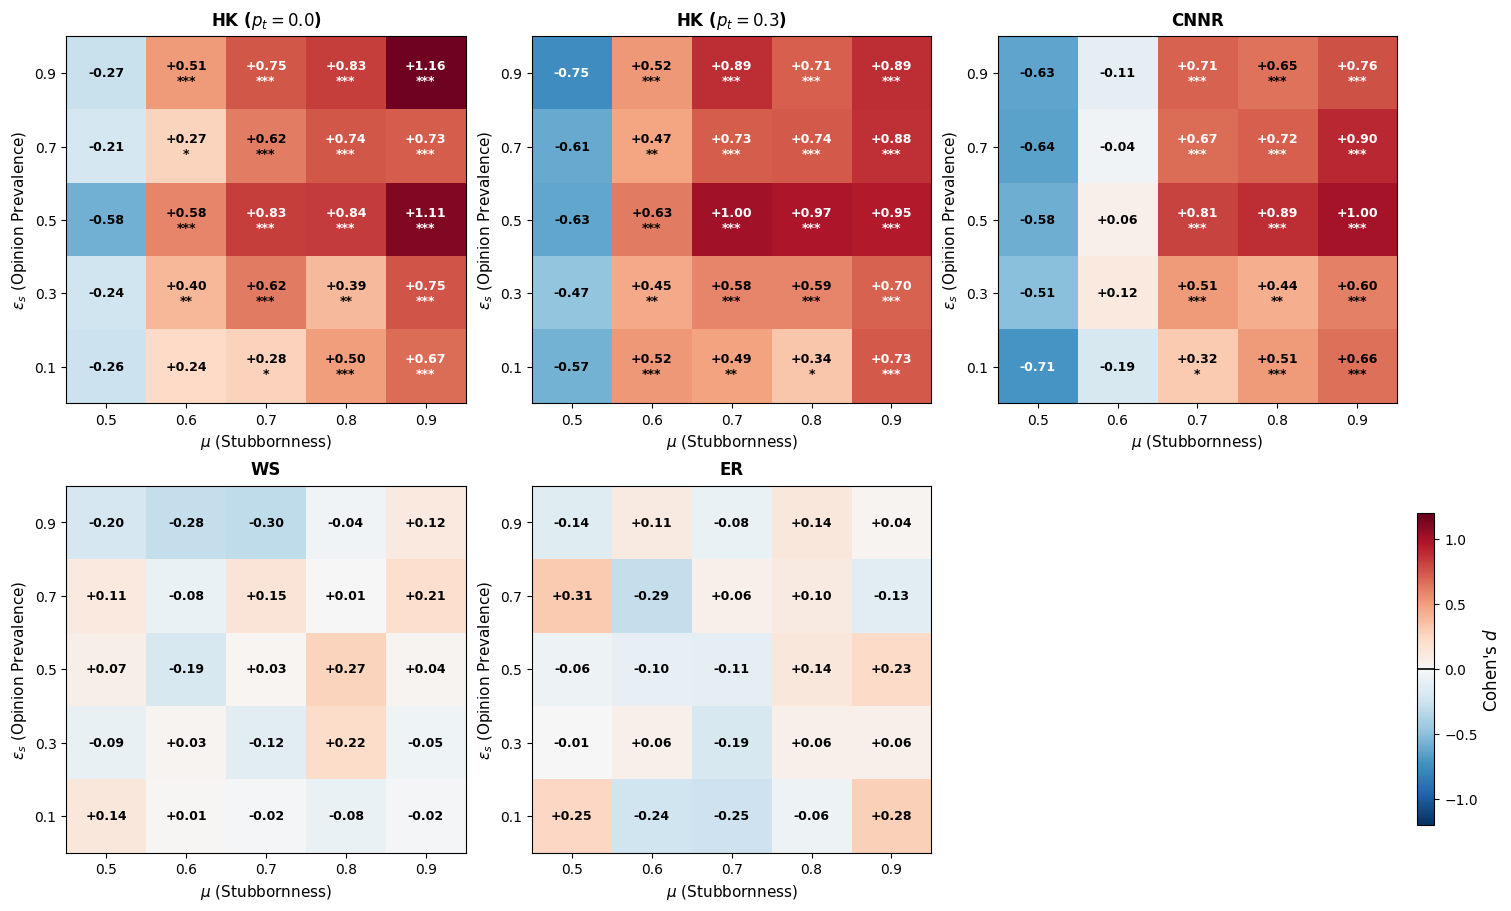

In [7]:
# ===========================================================================
# Heatmap — mu x epsilon_s -> Effect Size (Cohen's d)
# 3 rows x 2 cols panel layout:
#   Row 1 : HK (p_t=0.0)   HK (p_t=0.3)
#   Row 2 : CNNR           WS
#   Row 3 : ER             legend (colorbar)
# Color      : Cohen's d = mean / std  (diverging, blue=negative / red=positive).
# Annotation : d value + significance stars, Benjamini-Hochberg corrected WITHIN
#              each network's 25-cell (mu x epsilon_s) family (one-sample t-test
#              vs 0, alt='greater'; see bh_correct() docstring for the family choice).
# Title / footnote are intentionally omitted here; they are written in the LaTeX caption.
# ===========================================================================

import matplotlib.colors as mcolors

# --- Per-cell stats: (cohen_d, n, raw p-value) ---
cell_stats = {}
for (nw, mu, eps), grp in df_all.groupby(['nw_label', 'mu', 'epsilon_s']):
    cohen_d, n_seeds, p = cluster_stats(grp)   # seed-clustered: n_eff = #seeds
    if n_seeds < 2 or np.isnan(cohen_d):
        continue
    cell_stats[(nw, float(mu), float(eps))] = (cohen_d, n_seeds, p)

# --- BH-FDR correction, applied within each network's 25-cell family ---
cell_q = {}
for nw in {k[0] for k in cell_stats}:
    keys   = [k for k in cell_stats if k[0] == nw]
    pvals  = [cell_stats[k][2] for k in keys]
    qvals  = bh_correct(pvals)
    for k, q in zip(keys, qvals):
        cell_q[k] = q

# --- Report raw vs. BH-corrected significant-cell counts per network (for the TEX text) ---
print(f'{"network":38s} {"raw p<.05":>10s} {"BH q<.05":>10s}')
for nw in sorted({k[0] for k in cell_stats}):
    keys    = [k for k in cell_stats if k[0] == nw]
    n_raw   = sum(1 for k in keys if cell_stats[k][2] < 0.05)
    n_bh    = sum(1 for k in keys if cell_q[k] < 0.05)
    print(f'{nw:38s} {n_raw:>7d}/{len(keys):<3d} {n_bh:>7d}/{len(keys):<3d}')

# --- Colormap: symmetric diverging, centered at 0 ---
all_d = [v[0] for v in cell_stats.values()]
vmax  = np.ceil(max(abs(min(all_d)), abs(max(all_d))) * 10) / 10
norm  = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
CMAP  = 'RdBu_r'

# --- Explicit panel order with clean display names ---
# The raw nw_label strings carry network parameters (e.g. 'HolmeKim (A=1, m=2, pt=0.0)');
# match them robustly by topology prefix / p_t so the layout is independent of param values.
def _find(pred):
    return next((nw for nw in NW_STRUCTURES if pred(nw)), None)

PANEL_SPEC = [
    (_find(lambda s: s.startswith('HolmeKim') and 'pt=0.0' in s), r'HK ($p_t=0.0$)'),
    (_find(lambda s: s.startswith('HolmeKim') and 'pt=0.3' in s), r'HK ($p_t=0.3$)'),
    (_find(lambda s: s.startswith('CNNR')),                       'CNNR'),
    (_find(lambda s: s.startswith('WS')),                         'WS'),
    (_find(lambda s: s.startswith('ER')),                         'ER'),
]

fig, axes = plt.subplots(2, 3, figsize=(15.0, 9.0), constrained_layout=True)
axes_flat = axes.flatten()

plot_indices = [0, 1, 2, 3, 4]

for ax, (nw, disp) in zip([axes_flat[i] for i in plot_indices], PANEL_SPEC):
    if nw is None:
        ax.set_axis_off()
        continue

    sub      = df_cond[df_cond['nw_label'] == nw]
    mu_vals  = sorted(sub['mu'].unique())
    eps_vals = sorted(sub['epsilon_s'].unique(), reverse=True)

    nr, nc = len(eps_vals), len(mu_vals)
    grid_d = np.full((nr, nc), np.nan)
    grid_p = np.full((nr, nc), np.nan)

    for r, eps in enumerate(eps_vals):
        for c, mu in enumerate(mu_vals):
            key = (nw, float(mu), float(eps))
            if key in cell_stats:
                grid_d[r, c] = cell_stats[key][0]
                grid_p[r, c] = cell_q[key]  # BH-adjusted q-value drives the stars

    ax.imshow(grid_d, cmap=CMAP, norm=norm, aspect='auto')

    for r in range(nr):
        for c in range(nc):
            if np.isnan(grid_d[r, c]):
                ax.add_patch(plt.Rectangle(
                    (c - 0.5, r - 0.5), 1, 1,
                    hatch='////', fill=False, edgecolor='#aaaaaa', linewidth=0,
                ))
                ax.text(c, r, 'n/a', ha='center', va='center',
                        fontsize=8, color='#888888')
                continue
            dv    = grid_d[r, c]
            pv    = grid_p[r, c]
            stars = sig_stars(pv)
            txt_col = 'white' if abs(dv) > vmax * 0.55 else 'black'
            ax.text(c, r, f'{dv:+.2f}\n{stars}' if stars else f'{dv:+.2f}',
                    ha='center', va='center',
                    fontsize=9, color=txt_col, fontweight='bold', linespacing=1.2)

    ax.set_xticks(range(nc))
    ax.set_xticklabels([f'{v:.1f}' for v in mu_vals], fontsize=10)
    ax.set_yticks(range(nr))
    ax.set_yticklabels([f'{v:.1f}' for v in eps_vals], fontsize=10)
    ax.set_xlabel(r'$\mu$ (Stubbornness)', fontsize=11)
    ax.set_ylabel(r'$\epsilon_s$ (Opinion Prevalence)', fontsize=11)
    ax.set_title(disp, fontsize=12, fontweight='bold', pad=8)

# --- Legend (colorbar) occupies the 6th panel (row 3, col 2) ---
legend_ax = axes_flat[5]
legend_ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap=CMAP, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=legend_ax, fraction=0.5, shrink=0.85, aspect=18)
cbar.set_label(r"Cohen's $d$", fontsize=12)
cbar.ax.axhline(0, color='black', linewidth=1.2)

out_path = os.path.join(SUMMARY_ROOT, 'sensitivity_heatmap.png')
plt.savefig(out_path, dpi=300, bbox_inches='tight')
print(f'Saved -> {out_path}')
plt.show()


In [8]:
# ---------------------------------------------------------------------------
# Data coverage table
# Shows which (nw_label, mu, epsilon_s) cells are populated.
# Useful for planning which conditions to run next.
# ---------------------------------------------------------------------------
print('=== Conditions in data ===')
print(df_cond[['nw_label', 'mu', 'epsilon_s', 'n_samples', 'mean_backfire', 'std_backfire']]
      .to_string(index=False))

print('\n=== epsilon_s coverage per network structure ===')
print(df_all.groupby('nw_label')['epsilon_s'].apply(
    lambda x: sorted(x.dropna().unique())).to_string())

print('\n=== mu coverage per network structure ===')
print(df_all.groupby('nw_label')['mu'].apply(
    lambda x: sorted(x.dropna().unique())).to_string())

=== Conditions in data ===
                   nw_label  mu  epsilon_s  n_samples  mean_backfire  std_backfire
       CNNR (p=0.5, r=0.01) 0.5        0.1         84      -0.128752      0.776922
       CNNR (p=0.5, r=0.01) 0.5        0.3         84      -0.086761      0.560629
       CNNR (p=0.5, r=0.01) 0.5        0.5         80      -0.134184      0.692165
       CNNR (p=0.5, r=0.01) 0.5        0.7         84      -0.150790      0.786673
       CNNR (p=0.5, r=0.01) 0.5        0.9         78      -0.173232      0.731077
       CNNR (p=0.5, r=0.01) 0.6        0.1        100      -0.016689      0.482386
       CNNR (p=0.5, r=0.01) 0.6        0.3        100       0.010880      0.577536
       CNNR (p=0.5, r=0.01) 0.6        0.5        100       0.004754      0.540706
       CNNR (p=0.5, r=0.01) 0.6        0.7        100      -0.004050      0.619453
       CNNR (p=0.5, r=0.01) 0.6        0.9        100      -0.009415      0.526277
       CNNR (p=0.5, r=0.01) 0.7        0.1        100       

# Sensitivity Heatmap — Large Target Hub Only (Top 25% In-Degree)

Same heatmap as above, but restricted to seeds where the target agent's in-degree
at step 20 000 is **≥ 75th percentile within each network structure**.

Motivation: the baseline heatmap pools all random target selections regardless of
hub size.  This panel isolates runs where the target is genuinely high-degree,
making it possible to see whether the parameter sensitivity pattern changes when
the manipulation target is structurally influential.

Rows after join : 12,043  (expected ≈ 12,043)

Rows after top-25% in-degree filter: 3,025

75th-percentile in-degree by network structure:
nw_label
CNNR (p=0.5, r=0.01)           337.0
ER (p=0.002)                   162.0
HolmeKim (A=1, m=2, pt=0.0)    386.0
HolmeKim (A=1, m=2, pt=0.3)    523.0
WS (K=4, beta=0.1)             229.0

Seed counts per network structure after filter:
nw_label
CNNR (p=0.5, r=0.01)           604
ER (p=0.002)                   610
HolmeKim (A=1, m=2, pt=0.0)    622
HolmeKim (A=1, m=2, pt=0.3)    567
WS (K=4, beta=0.1)             622



Saved -> ./results/summary/sensitivity_heatmap_large_hub.png


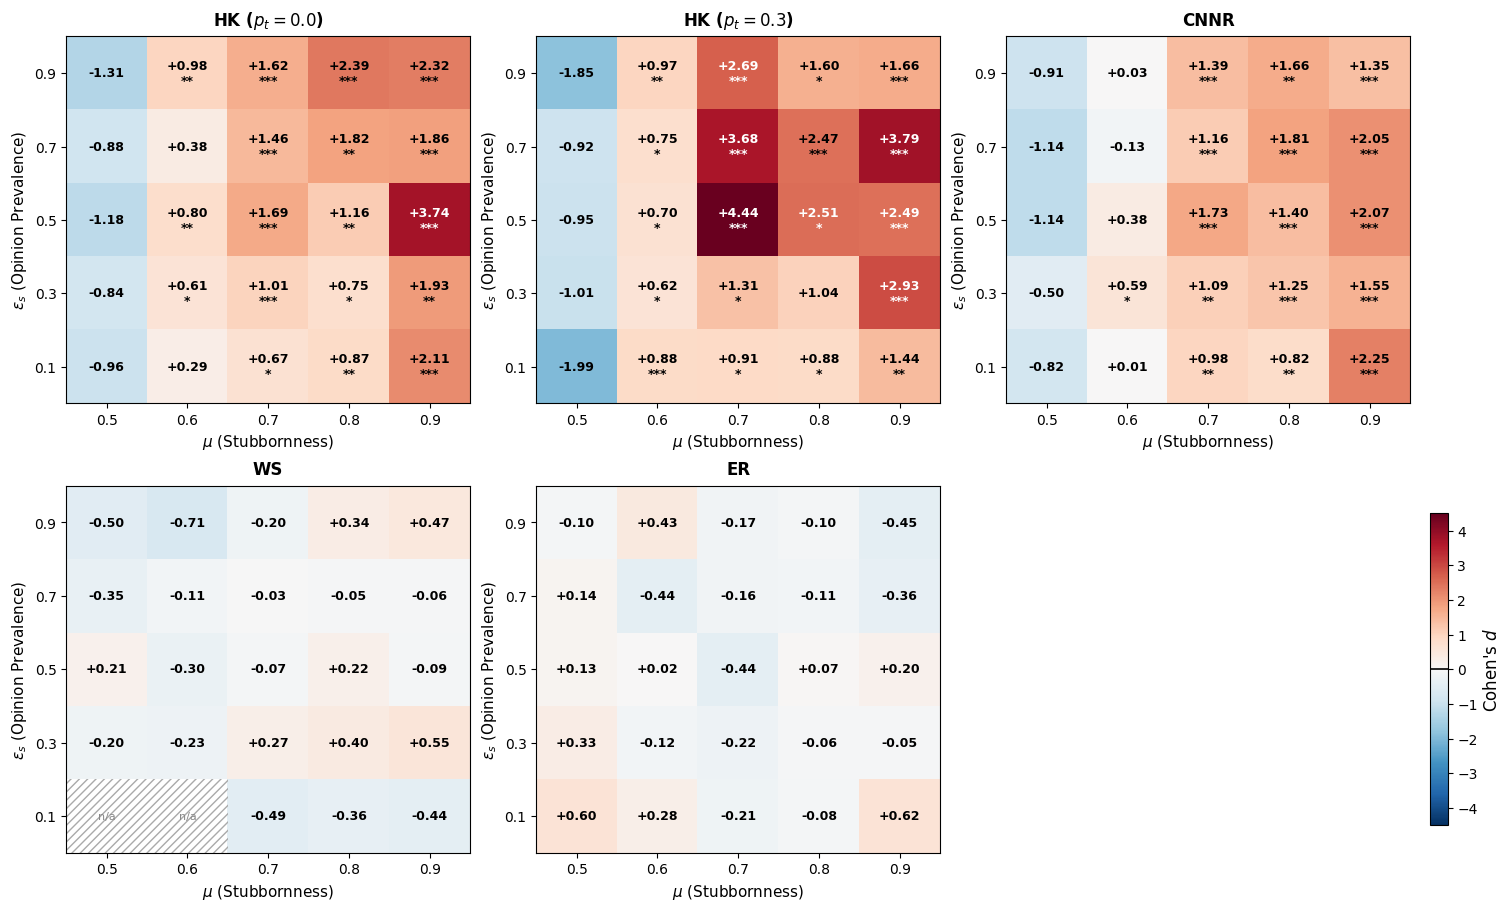

In [9]:
# ===========================================================================
# Heatmap (large hub only) — mu × epsilon_s → Cohen's d
# Subset: target in-degree ≥ 75th percentile within each network structure,
#         measured at step 20 000 (manipulation start).
# 3 rows x 2 cols panel layout (HK p_t=0.0 / HK p_t=0.3 / CNNR / WS / ER / legend).
# Title / footnote are intentionally omitted here; they are written in the LaTeX caption.
# ===========================================================================

# ── 1. Load target in-degree at MANIP_STEP ──────────────────────────────────
_hub_rows_lh = []
for _cfg in sorted(glob.glob(os.path.join(SUMMARY_ROOT, '*', '*', '*', 'config.yaml'))):
    _cdir   = os.path.dirname(_cfg)
    _hash   = os.path.basename(_cdir)
    _hpath  = os.path.join(_cdir, 'target_hub_metrics_5000step.csv')
    if os.path.exists(_hpath):
        _d = pd.read_csv(_hpath)
        _d['hash_id'] = _hash
        _hub_rows_lh.append(_d)

if not _hub_rows_lh:
    raise RuntimeError('target_hub_metrics_5000step.csv not found in any condition dir.')

df_hub_lh = pd.concat(_hub_rows_lh, ignore_index=True)
df_hub_lh['seed']        = df_hub_lh['seed'].astype(int)
df_hub_lh['target_sign'] = df_hub_lh['target_sign'].astype(float)

# keep only the snapshot at manipulation start
df_hub_20k_lh = (df_hub_lh[df_hub_lh['step'] == MANIP_STEP]
                 [['hash_id', 'seed', 'target_sign', 'in_degree']]
                 .copy())

# ── 2. Join in-degree with backfire rows and attach nw_label ─────────────────
_BF_KEY_COLS = ['hash_id', 'seed', 'target_sign', 'nw_label', 'mu', 'epsilon_s', 'backfire_effect']
df_bf_lh = df_all[_BF_KEY_COLS].copy()
df_bf_lh['seed']        = df_bf_lh['seed'].astype(int)
df_bf_lh['target_sign'] = df_bf_lh['target_sign'].astype(float)

df_merged_lh = df_bf_lh.merge(df_hub_20k_lh, on=['hash_id', 'seed', 'target_sign'], how='inner')
print(f'Rows after join : {len(df_merged_lh):,}  (expected ≈ {len(df_bf_lh):,})')

# ── 3. Compute 75th-percentile threshold per network structure ────────────────
# Quartile boundary is computed globally within each nw_label so the cutoff is
# consistent across all (mu, epsilon_s) cells of the same topology.
p75_by_nw = (df_merged_lh
             .groupby('nw_label')['in_degree']
             .quantile(0.75)
             .rename('p75_indegree'))
df_merged_lh = df_merged_lh.join(p75_by_nw, on='nw_label')

# filter to top 25 %
df_large_hub = df_merged_lh[df_merged_lh['in_degree'] >= df_merged_lh['p75_indegree']].copy()

print(f'\nRows after top-25% in-degree filter: {len(df_large_hub):,}')
print('\n75th-percentile in-degree by network structure:')
print(p75_by_nw.to_string())
print('\nSeed counts per network structure after filter:')
print(df_large_hub.groupby('nw_label')['seed'].count().to_string())

# ── 4. Per-cell stats: Cohen's d and one-sample t-test ───────────────────────
cell_stats_lh = {}
for (nw, mu, eps), grp in df_large_hub.groupby(['nw_label', 'mu', 'epsilon_s']):
    cohen_d, n_seeds, p = cluster_stats(grp)   # seed-clustered: n_eff = #seeds
    if n_seeds < 2 or np.isnan(cohen_d):
        continue
    cell_stats_lh[(nw, float(mu), float(eps))] = (cohen_d, n_seeds, p)

if not cell_stats_lh:
    raise RuntimeError('No valid cells after filtering — check that hub metrics are saved.')

# ── 5. Plot (3 rows x 2 cols; same panel order as the main heatmap) ──────────
all_d_lh = [v[0] for v in cell_stats_lh.values()]
vmax_lh   = np.ceil(max(abs(min(all_d_lh)), abs(max(all_d_lh))) * 10) / 10
norm_lh   = mcolors.TwoSlopeNorm(vmin=-vmax_lh, vcenter=0, vmax=vmax_lh)

# Explicit panel order with clean display names (matches the main heatmap).
def _find_lh(pred):
    return next((nw for nw in NW_STRUCTURES if pred(nw)), None)

PANEL_SPEC_LH = [
    (_find_lh(lambda s: s.startswith('HolmeKim') and 'pt=0.0' in s), r'HK ($p_t=0.0$)'),
    (_find_lh(lambda s: s.startswith('HolmeKim') and 'pt=0.3' in s), r'HK ($p_t=0.3$)'),
    (_find_lh(lambda s: s.startswith('CNNR')),                       'CNNR'),
    (_find_lh(lambda s: s.startswith('WS')),                         'WS'),
    (_find_lh(lambda s: s.startswith('ER')),                         'ER'),
]

fig, axes = plt.subplots(2, 3, figsize=(15.0, 9.0), constrained_layout=True)
axes_flat = axes.flatten()

for ax, (nw, disp) in zip(axes_flat[:5], PANEL_SPEC_LH):
    if nw is None:
        ax.set_axis_off()
        continue

    sub      = df_large_hub[df_large_hub['nw_label'] == nw]
    mu_vals  = sorted(sub['mu'].unique())
    eps_vals = sorted(sub['epsilon_s'].unique(), reverse=True)

    nr, nc = len(eps_vals), len(mu_vals)
    grid_d = np.full((nr, nc), np.nan)
    grid_p = np.full((nr, nc), np.nan)

    for r, eps in enumerate(eps_vals):
        for c, mu in enumerate(mu_vals):
            key = (nw, float(mu), float(eps))
            if key in cell_stats_lh:
                grid_d[r, c] = cell_stats_lh[key][0]
                grid_p[r, c] = cell_stats_lh[key][2]

    ax.imshow(grid_d, cmap=CMAP, norm=norm_lh, aspect='auto')

    for r in range(nr):
        for c in range(nc):
            if np.isnan(grid_d[r, c]):
                ax.add_patch(plt.Rectangle(
                    (c - 0.5, r - 0.5), 1, 1,
                    hatch='////', fill=False, edgecolor='#aaaaaa', linewidth=0,
                ))
                ax.text(c, r, 'n/a', ha='center', va='center',
                        fontsize=8, color='#888888')
                continue
            dv    = grid_d[r, c]
            pv    = grid_p[r, c]
            stars = sig_stars(pv)
            txt_col = 'white' if abs(dv) > vmax_lh * 0.55 else 'black'
            ax.text(c, r, f'{dv:+.2f}\n{stars}' if stars else f'{dv:+.2f}',
                    ha='center', va='center',
                    fontsize=9, color=txt_col, fontweight='bold', linespacing=1.2)

    ax.set_xticks(range(nc))
    ax.set_xticklabels([f'{v:.1f}' for v in mu_vals], fontsize=10)
    ax.set_yticks(range(nr))
    ax.set_yticklabels([f'{v:.1f}' for v in eps_vals], fontsize=10)
    ax.set_xlabel(r'$\mu$ (Stubbornness)', fontsize=11)
    ax.set_ylabel(r'$\epsilon_s$ (Opinion Prevalence)', fontsize=11)
    ax.set_title(disp, fontsize=12, fontweight='bold', pad=8)

# --- Legend (colorbar) occupies the 6th panel (row 3, col 2) ---
legend_ax = axes_flat[5]
legend_ax.set_axis_off()
sm_lh = plt.cm.ScalarMappable(cmap=CMAP, norm=norm_lh)
sm_lh.set_array([])
cbar_lh = fig.colorbar(sm_lh, ax=legend_ax, fraction=0.5, shrink=0.85, aspect=18)
cbar_lh.set_label(r"Cohen's $d$", fontsize=12)
cbar_lh.ax.axhline(0, color='black', linewidth=1.2)

out_path = os.path.join(SUMMARY_ROOT, 'sensitivity_heatmap_large_hub.png')
plt.savefig(out_path, dpi=300, bbox_inches='tight')
print(f'\nSaved -> {out_path}')
plt.show()


In [10]:
# ===========================================================================
# Load target hub metrics & global NW stats → join with backfire_effect
# ===========================================================================
# target_hub_metrics_5000step.csv : target agent centrality metrics per seed
# nw_stats_5000step.csv           : network-wide statistics per seed
# Both are keyed on (hash_id, seed, target_sign) at 5000-step snapshots.
# ===========================================================================

END_STEP   = 40000   # end of POST window

TARGET_STATS_COLS = [
    'in_degree', 'betweenness_gc', 'clustering', 'pagerank', 'eigenvector',
    'target_opinion', 'follower_mean_opinion', 'follower_opinion_std',
    'follower_homophily_frac', 'follower_dir_alignment',
]
GLOBAL_STATS_COLS = ['gamma', 'mean_in_degree', 'density', 'avg_clustering']

TARGET_STAT_LABELS = {
    'in_degree'              : 'In-Degree',
    'betweenness_gc'         : 'Betweenness (GC)',
    'clustering'             : 'Clustering',
    'pagerank'               : 'PageRank',
    'eigenvector'            : 'Eigenvector',
    'target_opinion'         : 'Target Opinion',
    'follower_mean_opinion'  : 'Follower Mean Opinion',
    'follower_opinion_std'   : 'Follower Opinion Std',
    'follower_homophily_frac': 'Follower Homophily',
    'follower_dir_alignment' : 'Follower Dir. Alignment',
}
GLOBAL_STAT_LABELS = {
    'gamma'          : r'Power-law $\gamma$',
    'mean_in_degree' : 'Mean In-Degree',
    'density'        : 'Network Density',
    'avg_clustering' : 'Avg Clustering',
}

# --- scan all condition dirs ---
hub_rows, nw_rows = [], []

for cfg_path in sorted(glob.glob(os.path.join(SUMMARY_ROOT, '*', '*', '*', 'config.yaml'))):
    cond_dir = os.path.dirname(cfg_path)
    hash_id  = os.path.basename(cond_dir)

    hub_path = os.path.join(cond_dir, 'target_hub_metrics_5000step.csv')
    if os.path.exists(hub_path):
        d = pd.read_csv(hub_path)
        d['hash_id'] = hash_id
        hub_rows.append(d)

    nw_path = os.path.join(cond_dir, 'nw_stats_5000step.csv')
    if os.path.exists(nw_path):
        d = pd.read_csv(nw_path)
        d['hash_id'] = hash_id
        nw_rows.append(d)

df_hub_all = pd.concat(hub_rows, ignore_index=True) if hub_rows else pd.DataFrame()
df_nw_all  = pd.concat(nw_rows,  ignore_index=True) if nw_rows  else pd.DataFrame()

# normalise join-key dtypes
for df_ in [df_hub_all, df_nw_all]:
    df_['seed']        = df_['seed'].astype(int)
    df_['target_sign'] = df_['target_sign'].astype(float)

# backfire key (one row per seed×direction×condition)
_BF_COLS = ['hash_id', 'seed', 'target_sign', 'nw_label', 'mu', 'epsilon_s', 'backfire_effect']
df_bf = df_all[_BF_COLS].copy()
df_bf['seed']        = df_bf['seed'].astype(int)
df_bf['target_sign'] = df_bf['target_sign'].astype(float)

# --- join target hub metrics at MANIP_STEP ---
df_hub_20k = (df_hub_all[df_hub_all['step'] == MANIP_STEP]
              .drop(columns='step')
              .reset_index(drop=True))
df_target  = df_bf.merge(df_hub_20k, on=['hash_id', 'seed', 'target_sign'], how='inner')

# --- join global NW stats (retain all steps; filter per plot) ---
df_nw_merged = df_bf.merge(df_nw_all, on=['hash_id', 'seed', 'target_sign'], how='inner')

print(f'Target hub stats joined : {len(df_target):,} rows  (expected ≈ {len(df_bf):,})')
print(f'Global NW stats joined  : {len(df_nw_merged):,} rows')
print(f'Available steps         : {sorted(df_nw_merged["step"].unique())}')
missing = len(df_bf) - len(df_target)
if missing:
    print(f'WARNING: {missing} backfire rows could not be joined (missing hub metrics)')

Target hub stats joined : 12,043 rows  (expected ≈ 12,043)
Global NW stats joined  : 108,387 rows
Available steps         : [np.int64(0), np.int64(5000), np.int64(10000), np.int64(15000), np.int64(20000), np.int64(25000), np.int64(30000), np.int64(35000), np.int64(40000)]


Saved → ./results/summary/scatter_target_stats_20000.png


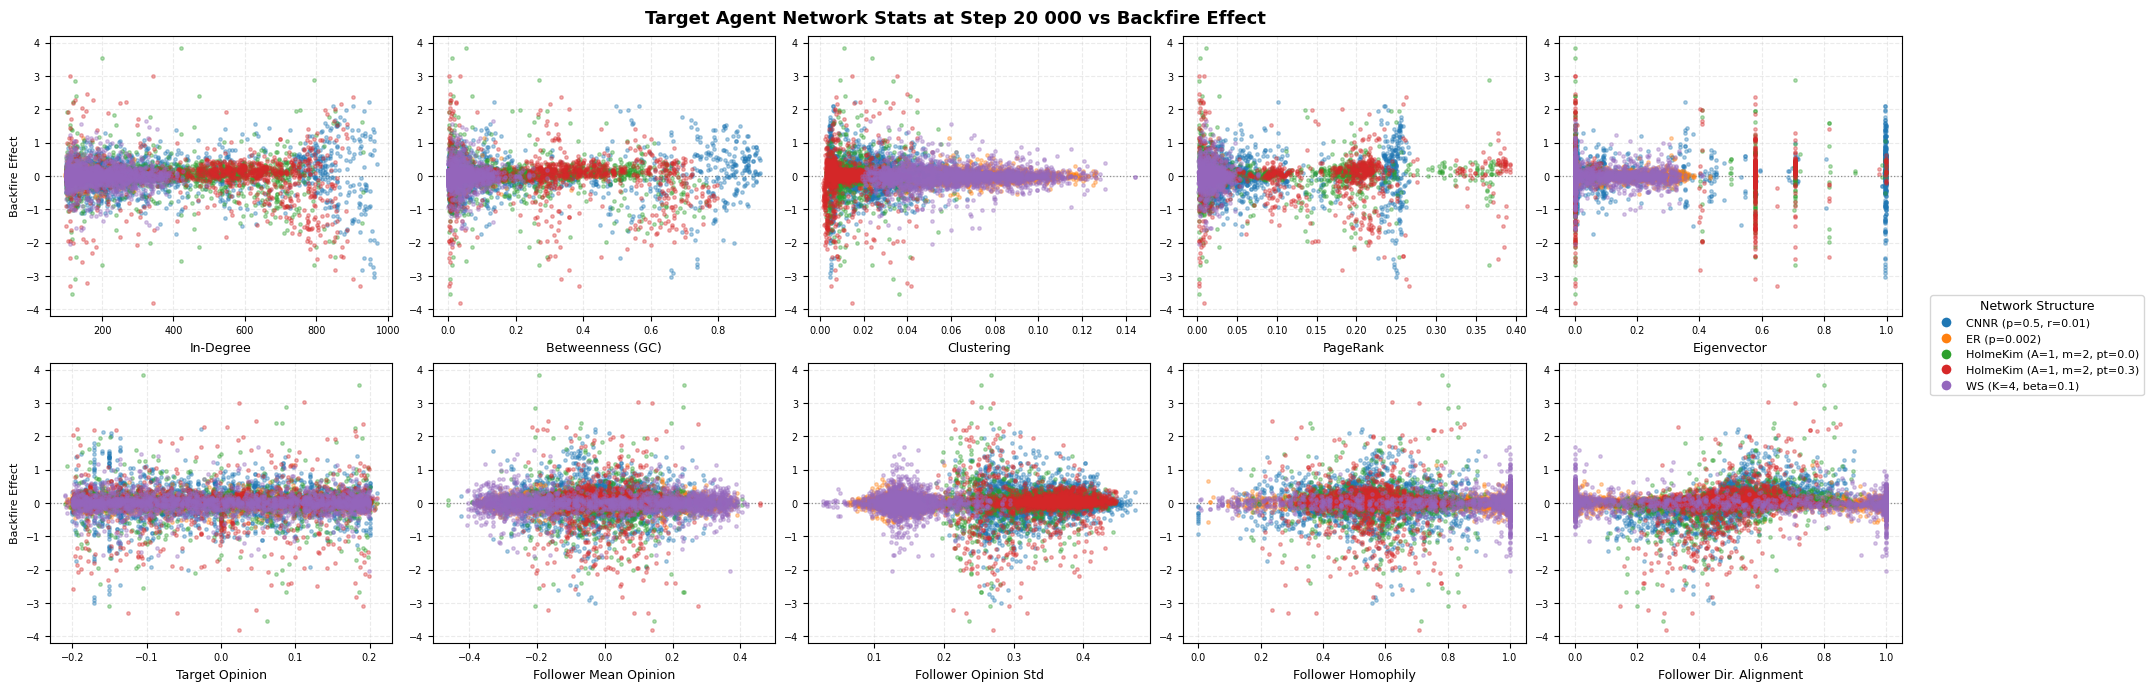

In [11]:
# ===========================================================================
# Plot 3 — Target Agent NW Stats at Step 20000 vs Backfire Effect
# ===========================================================================
# Each point = one (seed, direction, condition).
# Color = network structure (NW_COLOR).  No connecting lines.
# 2 rows × 5 cols grid, one subplot per metric.
# ===========================================================================

_NCOLS = 5
_NROWS = int(np.ceil(len(TARGET_STATS_COLS) / _NCOLS))

fig, axes = plt.subplots(_NROWS, _NCOLS,
                         figsize=(_NCOLS * 3.8, _NROWS * 3.4),
                         constrained_layout=True)
axes = axes.flatten()

_legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=NW_COLOR[nw], markersize=8, label=nw)
    for nw in NW_STRUCTURES
]

for i, stat in enumerate(TARGET_STATS_COLS):
    ax = axes[i]
    for nw in NW_STRUCTURES:
        sub = df_target[df_target['nw_label'] == nw].dropna(subset=[stat])
        if sub.empty:
            continue
        ax.scatter(
            sub[stat], sub['backfire_effect'],
            color=NW_COLOR[nw], s=6, alpha=0.35, zorder=3, rasterized=True,
        )
    ax.axhline(0, color='#888888', linestyle=':', linewidth=0.9, zorder=1)
    ax.set_xlabel(TARGET_STAT_LABELS.get(stat, stat), fontsize=9)
    ax.set_ylabel('Backfire Effect', fontsize=8) if i % _NCOLS == 0 else ax.set_ylabel('')
    ax.grid(True, linestyle='--', alpha=0.25)
    ax.tick_params(labelsize=7)

for j in range(len(TARGET_STATS_COLS), len(axes)):
    axes[j].set_visible(False)

fig.legend(handles=_legend_handles,
           title='Network Structure', title_fontsize=9, fontsize=8,
           loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.suptitle('Target Agent Network Stats at Step 20 000 vs Backfire Effect',
             fontsize=13, fontweight='bold')

out_path = os.path.join(SUMMARY_ROOT, 'scatter_target_stats_20000.png')
plt.savefig(out_path, dpi=200, bbox_inches='tight')
print(f'Saved → {out_path}')
plt.show()

Saved → ./results/summary/scatter_target_stats_20000_cnnr_hk.png


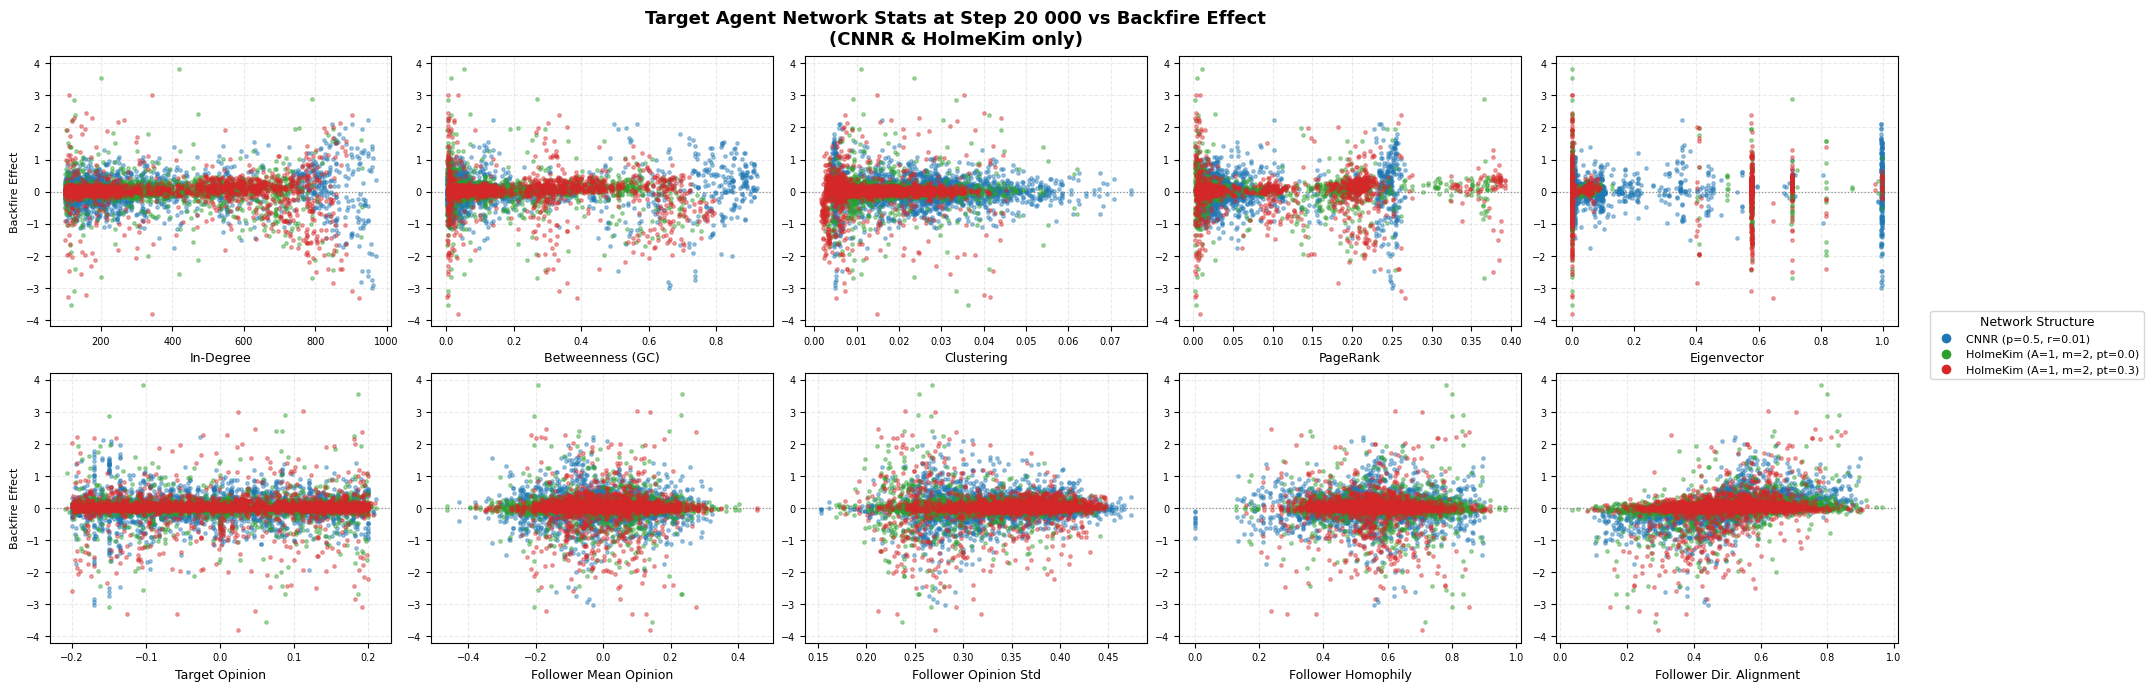

In [12]:
# ===========================================================================
# Plot 3b — Same as above, CNNR and HolmeKim only (excluding WS and ER)
# ===========================================================================

_NW_FOCUS = [nw for nw in NW_STRUCTURES if nw.startswith('CNNR') or nw.startswith('HolmeKim')]

fig, axes = plt.subplots(_NROWS, _NCOLS,
                         figsize=(_NCOLS * 3.8, _NROWS * 3.4),
                         constrained_layout=True)
axes = axes.flatten()

_legend_handles_focus = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=NW_COLOR[nw], markersize=8, label=nw)
    for nw in _NW_FOCUS
]

for i, stat in enumerate(TARGET_STATS_COLS):
    ax = axes[i]
    for nw in _NW_FOCUS:
        sub = df_target[df_target['nw_label'] == nw].dropna(subset=[stat])
        if sub.empty:
            continue
        ax.scatter(
            sub[stat], sub['backfire_effect'],
            color=NW_COLOR[nw], s=6, alpha=0.4, zorder=3, rasterized=True,
        )
    ax.axhline(0, color='#888888', linestyle=':', linewidth=0.9, zorder=1)
    ax.set_xlabel(TARGET_STAT_LABELS.get(stat, stat), fontsize=9)
    ax.set_ylabel('Backfire Effect', fontsize=8) if i % _NCOLS == 0 else ax.set_ylabel('')
    ax.grid(True, linestyle='--', alpha=0.25)
    ax.tick_params(labelsize=7)

for j in range(len(TARGET_STATS_COLS), len(axes)):
    axes[j].set_visible(False)

fig.legend(handles=_legend_handles_focus,
           title='Network Structure', title_fontsize=9, fontsize=8,
           loc='center left', bbox_to_anchor=(1.01, 0.5))
fig.suptitle('Target Agent Network Stats at Step 20 000 vs Backfire Effect\n(CNNR & HolmeKim only)',
             fontsize=13, fontweight='bold')

out_path = os.path.join(SUMMARY_ROOT, 'scatter_target_stats_20000_cnnr_hk.png')
plt.savefig(out_path, dpi=200, bbox_inches='tight')
print(f'Saved → {out_path}')
plt.show()

# Stratified Analysis — Backfire by Target Centrality Tier

The random target selection (>100 followers) pools a wide range of node types.
These plots ask: **does backfire scale with the target's structural influence?**

Quartiles are computed *within* each network structure so that degree distributions
across different topologies do not confound the ranking.

Saved → ./results/summary/stratified_by_centrality.png


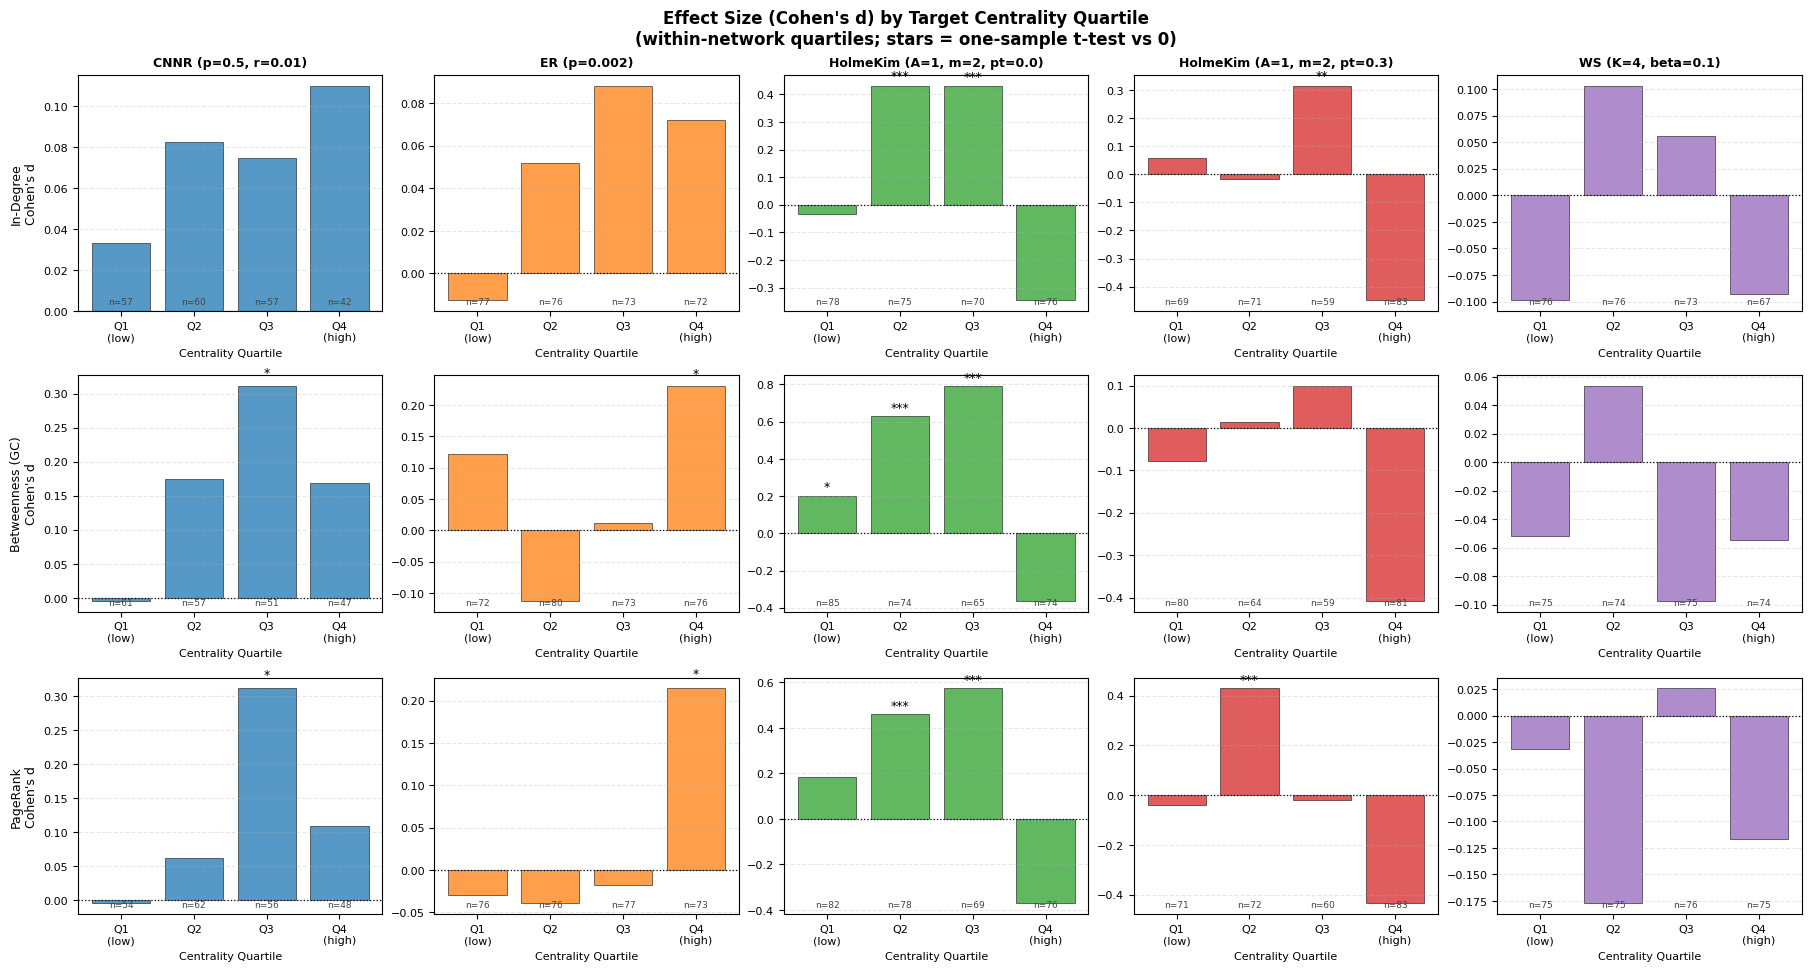


=== Cohen's d by In-Degree Quartile ===
                   nw_label  quartile  cohen_d      p  n
       CNNR (p=0.5, r=0.01)  Q1 (low)    0.033 0.4016 57
       CNNR (p=0.5, r=0.01)        Q2    0.082 0.2627 60
       CNNR (p=0.5, r=0.01)        Q3    0.075 0.2877 57
       CNNR (p=0.5, r=0.01) Q4 (high)    0.110 0.2402 42
               ER (p=0.002)  Q1 (low)   -0.013 0.5440 77
               ER (p=0.002)        Q2    0.052 0.3257 76
               ER (p=0.002)        Q3    0.088 0.2269 73
               ER (p=0.002) Q4 (high)    0.072 0.2713 72
HolmeKim (A=1, m=2, pt=0.0)  Q1 (low)   -0.033 0.6143 78
HolmeKim (A=1, m=2, pt=0.0)        Q2    0.432 0.0002 75
HolmeKim (A=1, m=2, pt=0.0)        Q3    0.430 0.0003 70
HolmeKim (A=1, m=2, pt=0.0) Q4 (high)   -0.347 0.9983 76
HolmeKim (A=1, m=2, pt=0.3)  Q1 (low)    0.058 0.3146 69
HolmeKim (A=1, m=2, pt=0.3)        Q2   -0.018 0.5607 71
HolmeKim (A=1, m=2, pt=0.3)        Q3    0.317 0.0090 59
HolmeKim (A=1, m=2, pt=0.3) Q4 (high)   -0.449 

In [13]:
# ===========================================================================
# Stratification: effect size (Cohen's d) by target centrality quartile
# Quartiles computed within each network structure.
# Bar height = Cohen's d per group; stars = one-sample t-test vs 0.
# ===========================================================================

STRAT_METRICS = {
    'in_degree'  : 'In-Degree',
    'betweenness_gc': 'Betweenness (GC)',
    'pagerank'   : 'PageRank',
}
QTILE_NAMES = ['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)']


def _safe_qcut(x, q=4, all_labels=None):
    """pd.cut with quantile-derived edges, robust to skewed distributions.

    When many values are identical (e.g. betweenness=0 for most nodes),
    np.unique collapses duplicate edges so the label count always matches
    the actual number of resulting bins.  Returns object dtype so that
    groupby.transform can concatenate groups with different category sets.
    """
    if all_labels is None:
        all_labels = [f'Q{i+1}' for i in range(q)]
    unique_edges = np.unique(x.dropna().quantile(np.linspace(0, 1, q + 1)).values)
    n_bins = len(unique_edges) - 1
    if n_bins < 1:
        return pd.Series(np.nan, index=x.index, dtype='object')
    labels = all_labels[:n_bins]
    result = pd.cut(x, bins=unique_edges, labels=labels, include_lowest=True)
    return result.astype(object)   # avoid CategoricalDtype merge issues in transform


df_strat = df_target.copy()
for metric in STRAT_METRICS:
    df_strat[f'{metric}_q'] = (
        df_strat
        .groupby('nw_label')[metric]
        .transform(lambda x: _safe_qcut(x, q=4, all_labels=QTILE_NAMES))
    )


def cohen_d_and_p(df):
    """Seed-clustered (d, p): aggregate to seed means, then d & one-sample t vs 0.
    `df` must carry the 'seed' and 'backfire_effect' columns."""
    d, n, p = cluster_stats(df)
    return (d, p)


n_metrics = len(STRAT_METRICS)
n_nw      = len(NW_STRUCTURES)

fig, axes = plt.subplots(n_metrics, n_nw,
                         figsize=(n_nw * 3.6, n_metrics * 3.2),
                         constrained_layout=True)

for row, (metric, mlabel) in enumerate(STRAT_METRICS.items()):
    for col, nw in enumerate(NW_STRUCTURES):
        ax  = axes[row, col]
        sub = df_strat[df_strat['nw_label'] == nw].dropna(subset=[f'{metric}_q'])

        # use set of unique values — column is object dtype, not Categorical
        present = set(sub[f'{metric}_q'].unique())
        qs = [q for q in QTILE_NAMES if q in present]
        ds, ps, ns = [], [], []
        for q in qs:
            sub_q = sub[sub[f'{metric}_q'] == q]
            d, p = cohen_d_and_p(sub_q)
            ds.append(d); ps.append(p); ns.append(sub_q['seed'].nunique())

        ax.bar(range(len(qs)), ds, capsize=4,
               color=NW_COLOR[nw], alpha=0.75, edgecolor='black', linewidth=0.5)
        ax.axhline(0, color='black', linewidth=0.9, linestyle=':')
        ax.set_xticks(range(len(qs)))
        ax.set_xticklabels([q.replace(' (', '\n(') for q in qs], fontsize=8)

        for i, (d, p) in enumerate(zip(ds, ps)):
            stars = sig_stars(p) if not np.isnan(p) else ''
            if stars:
                ax.text(i, d + 0.01, stars, ha='center', va='bottom',
                        fontsize=9, color='black')

        xform = ax.get_xaxis_transform()
        for i, n in enumerate(ns):
            ax.text(i, 0.02, f'n={n}', ha='center', va='bottom',
                    fontsize=6.5, color='#444444', transform=xform)

        if col == 0:
            ax.set_ylabel(f"{mlabel}\nCohen's d", fontsize=9)
        if row == 0:
            ax.set_title(nw, fontsize=9, fontweight='bold')
        ax.set_xlabel('Centrality Quartile', fontsize=8)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        ax.tick_params(labelsize=8)

fig.suptitle(
    "Effect Size (Cohen's d) by Target Centrality Quartile\n"
    '(within-network quartiles; stars = one-sample t-test vs 0)',
    fontsize=12, fontweight='bold',
)
out_path = os.path.join(SUMMARY_ROOT, 'stratified_by_centrality.png')
plt.savefig(out_path, dpi=200, bbox_inches='tight')
print(f'Saved → {out_path}')
plt.show()

# --- Numeric summary ---
print("\n=== Cohen's d by In-Degree Quartile ===")
rows = []
for nw in NW_STRUCTURES:
    sub = df_strat[df_strat['nw_label'] == nw].dropna(subset=['in_degree_q'])
    for q in QTILE_NAMES:
        sub_q = sub[sub['in_degree_q'] == q]
        d, p = cohen_d_and_p(sub_q)
        rows.append({'nw_label': nw, 'quartile': q,
                     'cohen_d': round(d, 3), 'p': round(p, 4), 'n': sub_q['seed'].nunique()})
print(pd.DataFrame(rows).to_string(index=False))

Saved → ./results/summary/stratified_indegree_by_mu.png


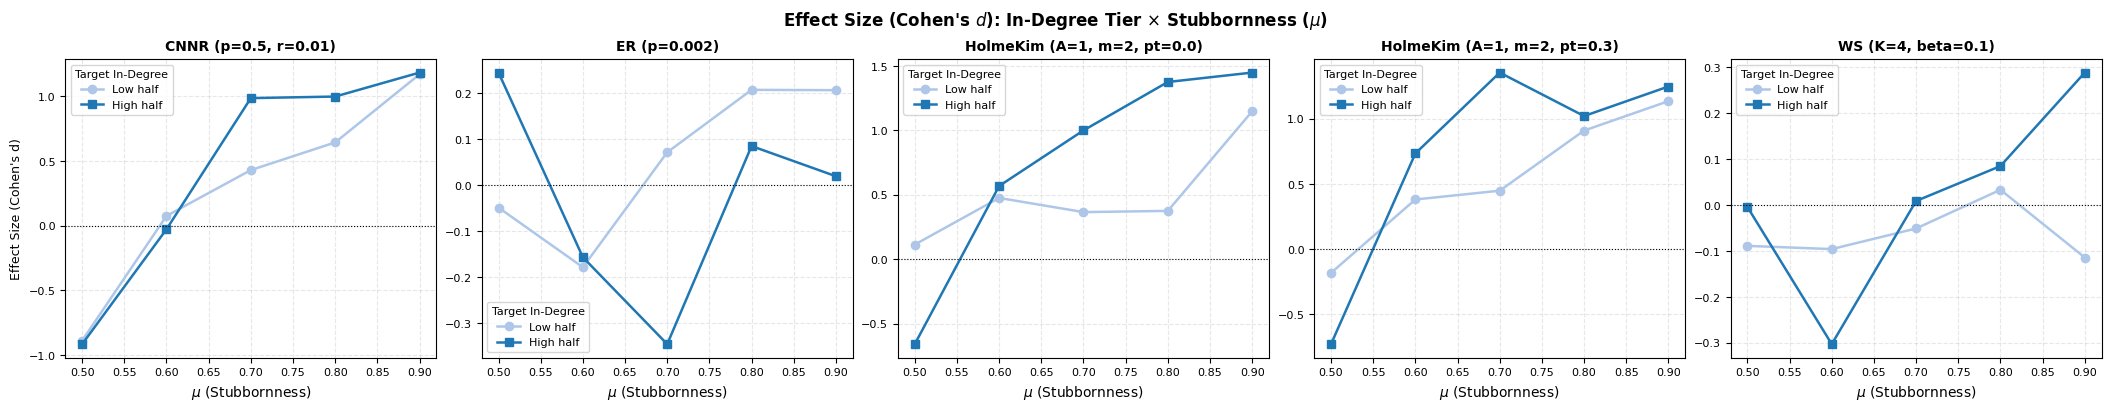


=== Cohen's d: High-half vs Low-half by (nw_label, mu) ===
                   nw_label  mu  d_high  d_low  gap (high-low)
       CNNR (p=0.5, r=0.01) 0.5  -0.914 -0.887          -0.027
       CNNR (p=0.5, r=0.01) 0.6  -0.027  0.075          -0.103
       CNNR (p=0.5, r=0.01) 0.7   0.985  0.429           0.555
       CNNR (p=0.5, r=0.01) 0.8   0.997  0.643           0.354
       CNNR (p=0.5, r=0.01) 0.9   1.182  1.168           0.013
               ER (p=0.002) 0.5   0.245 -0.049           0.294
               ER (p=0.002) 0.6  -0.157 -0.179           0.022
               ER (p=0.002) 0.7  -0.346  0.071          -0.417
               ER (p=0.002) 0.8   0.085  0.207          -0.122
               ER (p=0.002) 0.9   0.019  0.207          -0.187
HolmeKim (A=1, m=2, pt=0.0) 0.5  -0.660  0.113          -0.773
HolmeKim (A=1, m=2, pt=0.0) 0.6   0.568  0.475           0.093
HolmeKim (A=1, m=2, pt=0.0) 0.7   1.000  0.365           0.634
HolmeKim (A=1, m=2, pt=0.0) 0.8   1.376  0.375           1

In [14]:
# ===========================================================================
# Interaction: effect size (Cohen's d) — in-degree tier × mu
# Answers: does targeting a higher-degree node matter more at high or low mu?
# ===========================================================================

HALF_LABELS  = ['Low half', 'High half']
HALF_COLORS  = {'Low half': '#aec7e8', 'High half': '#1f77b4'}
HALF_MARKERS = {'Low half': 'o',       'High half': 's'}

df_strat['in_degree_half'] = (
    df_strat
    .groupby('nw_label')['in_degree']
    .transform(lambda x: _safe_qcut(x, q=2, all_labels=HALF_LABELS))
)

mu_all = sorted(df_strat['mu'].unique())

fig, axes = plt.subplots(1, n_nw, figsize=(n_nw * 4.2, 4.0), constrained_layout=True)

for col, nw in enumerate(NW_STRUCTURES):
    ax  = axes[col]
    sub = df_strat[df_strat['nw_label'] == nw].dropna(subset=['in_degree_half'])

    for half in HALF_LABELS:
        mu_avail, ds = [], []
        for mu in mu_all:
            vals = sub[(sub['in_degree_half'] == half) & (sub['mu'] == mu)]
            if vals['seed'].nunique() < 2:
                continue
            d, _ = cohen_d_and_p(vals)
            mu_avail.append(mu); ds.append(d)

        ax.plot(mu_avail, ds,
                marker=HALF_MARKERS[half], label=half,
                color=HALF_COLORS[half], linewidth=1.8, markersize=6)

    ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
    ax.set_xlabel(r'$\mu$ (Stubbornness)', fontsize=10)
    if col == 0:
        ax.set_ylabel("Effect Size (Cohen's d)", fontsize=9)
    ax.set_title(nw, fontsize=10, fontweight='bold')
    ax.legend(title='Target In-Degree', fontsize=8, title_fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(labelsize=8)

fig.suptitle(
    r"Effect Size (Cohen's $d$): In-Degree Tier $\times$ Stubbornness ($\mu$)",
    fontsize=12, fontweight='bold',
)
out_path = os.path.join(SUMMARY_ROOT, 'stratified_indegree_by_mu.png')
plt.savefig(out_path, dpi=200, bbox_inches='tight')
print(f'Saved → {out_path}')
plt.show()

# --- gap table ---
print("\n=== Cohen's d: High-half vs Low-half by (nw_label, mu) ===")
gap_rows = []
for nw in NW_STRUCTURES:
    sub = df_strat[df_strat['nw_label'] == nw].dropna(subset=['in_degree_half'])
    for mu in mu_all:
        mu_sub = sub[sub['mu'] == mu]
        d_hi, _ = cohen_d_and_p(mu_sub[mu_sub['in_degree_half'] == 'High half'])
        d_lo, _ = cohen_d_and_p(mu_sub[mu_sub['in_degree_half'] == 'Low half' ])
        gap_rows.append({'nw_label': nw, 'mu': mu,
                         'd_high': round(d_hi, 3), 'd_low': round(d_lo, 3),
                         'gap (high-low)': round(d_hi - d_lo, 3)})
print(pd.DataFrame(gap_rows).to_string(index=False))

# Dose-Response Table and Continuous Correlation (Table tab:doseresponse)

Tests whether the backfire effect is **gated** by hub centrality at the trial level, pooled across the **backfire-active regime**: the heavy-tailed networks (CNNR, HK $p_t{=}0.0$, HK $p_t{=}0.3$) at $\mu \geq 0.7$ (45 conditions, 4{,}294 trials). This isolates the manipulated target's own in-degree from the aggregate topology effect (see paper Sec. Sensitivity Analysis).

Two analyses:

1. **Quartile binning** — per-trial $b$ split into four **within-condition** in-degree quartiles (quartile cutoffs computed separately per condition, then pooled); reports $n$, mean $b$, Cohen's $d$, and one-sided $t$-test $p$ per bin (-> Table `tab:doseresponse`).
2. **Continuous Spearman** — pooled $\rho(b, \text{in-degree})$ and the within-condition demeaned version (removes each condition's own mean from both $b$ and in-degree before correlating, so between-condition variation cannot drive it), plus the count of conditions with a positive per-condition $\rho$ (45/45 expected).

In [15]:
# ===========================================================================
# Dose-response: per-trial b vs target in-degree quartile   (Table tab:doseresponse)
# Pooled backfire-active regime: heavy-tailed networks (CNNR, HK pt=0.0, HK
# pt=0.3) at mu >= 0.7 (45 conditions, 4,294 trials). Quartiles are computed
# WITHIN each condition (hash_id) so topology/parameter differences in the
# raw in-degree scale do not confound the binning.
# Depends on df_target (Cell 10, hub metrics at step 20000 joined to backfire).
# ===========================================================================

_HEAVY_TAILED_NW = [
    'CNNR (p=0.5, r=0.01)',
    'HolmeKim (A=1, m=2, pt=0.0)',
    'HolmeKim (A=1, m=2, pt=0.3)',
]
_DOSE_MU_MIN = 0.7

df_dose = df_target[
    df_target['nw_label'].isin(_HEAVY_TAILED_NW) &
    (df_target['mu'] >= _DOSE_MU_MIN)
].copy()

print(f"Pooled backfire-active regime: {df_dose['hash_id'].nunique()} conditions, "
      f"{len(df_dose):,} trials")
print(df_dose.groupby('nw_label')['hash_id'].nunique())

# quartile bins on in_degree, computed WITHIN each condition
df_dose['q'] = df_dose.groupby('hash_id')['in_degree'].transform(
    lambda x: pd.qcut(x, 4, labels=['Q1', 'Q2', 'Q3', 'Q4']))

# Seed-clustering must key on (hash_id, seed): pooling 45 conditions means raw
# seed numbers repeat across conditions/topologies, so clustering on 'seed'
# alone would wrongly merge unrelated trials. cluster_stats() takes any column
# name, so we build a compound key and pass that.
df_dose['cluster_key'] = df_dose['hash_id'].astype(str) + '_' + df_dose['seed'].astype(str)

# --- Table tab:doseresponse -------------------------------------------------
print()
print('=== Table tab:doseresponse (pooled, mu >= 0.7, 45 conditions) ===')
print()
hdr = f"{'Group':<24} {'n':>5}  {'mean b':>8}  {'std b':>7}  {'Cohen d':>8}  {'p':>10}"
print(hdr)
print('-' * len(hdr))

d_all, n_all, p_all = cluster_stats(df_dose, cluster='cluster_key')
print(f"  {'All targets (baseline)':<22} {len(df_dose):>5}  {df_dose['backfire_effect'].mean():>+8.3f}  "
      f"{df_dose['backfire_effect'].std(ddof=1):>7.3f}  {d_all:>+8.2f}  {p_all:>10.1e}")
print('-' * len(hdr))

for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    sub = df_dose[df_dose['q'] == q]
    dq, nq, pq = cluster_stats(sub, cluster='cluster_key')
    print(f"  {q:<22} {len(sub):>5}  {sub['backfire_effect'].mean():>+8.3f}  "
          f"{sub['backfire_effect'].std(ddof=1):>7.3f}  {dq:>+8.2f}  {pq:>10.1e}")

# --- Spearman(b, in-degree) -------------------------------------------------
rho_pooled, p_pooled = stats.spearmanr(df_dose['in_degree'], df_dose['backfire_effect'])
print()
print(f'=== Spearman(b, in-degree) — pooled, raw (n={len(df_dose)}) ===')
print(f'  rho = {rho_pooled:+.4f},  p = {p_pooled:.2e}')

# within-condition demeaned: removes each condition's own mean from both
# variables so between-condition variation cannot drive the correlation.
df_dose['b_resid']   = (df_dose['backfire_effect']
                        - df_dose.groupby('hash_id')['backfire_effect'].transform('mean'))
df_dose['deg_resid'] = (df_dose['in_degree']
                        - df_dose.groupby('hash_id')['in_degree'].transform('mean'))
rho_wc, p_wc = stats.spearmanr(df_dose['deg_resid'], df_dose['b_resid'])
print()
print(f'=== Spearman(b, in-degree) — within-condition demeaned (n={len(df_dose)}) ===')
print(f'  rho = {rho_wc:+.4f},  p = {p_wc:.2e}')

# per-condition sign check
n_pos = sum(1 for _, g in df_dose.groupby('hash_id')
            if stats.spearmanr(g['in_degree'], g['backfire_effect'])[0] > 0)
n_cond = df_dose['hash_id'].nunique()
print()
print(f'=== Per-condition Spearman sign ===')
print(f'  {n_pos}/{n_cond} conditions have rho(b, in-degree) > 0')
print()
print('Interpretation:')
print(f'  Pooled within-condition rho={rho_wc:+.3f} (p={p_wc:.1e}), positive in {n_pos}/{n_cond} conditions:')
print('  the per-trial backfire magnitude rises with the manipulated hub\'s own in-degree,')
print('  isolating structural prominence from the aggregate topology contrast (Fig 2).')


Pooled backfire-active regime: 45 conditions, 4,294 trials
nw_label
CNNR (p=0.5, r=0.01)           15
HolmeKim (A=1, m=2, pt=0.0)    15
HolmeKim (A=1, m=2, pt=0.3)    15
Name: hash_id, dtype: int64

=== Table tab:doseresponse (pooled, mu >= 0.7, 45 conditions) ===

Group                        n    mean b    std b   Cohen d           p
-----------------------------------------------------------------------
  All targets (baseline)  4294    +0.059    0.203     +0.66    5.5e-169
-----------------------------------------------------------------------
  Q1                      1124    +0.018    0.118     +0.42     1.1e-21
  Q2                      1038    +0.026    0.132     +0.57     3.1e-34
  Q3                      1096    +0.046    0.151     +0.80     1.2e-60
  Q4                      1036    +0.149    0.321     +1.24    5.0e-107

=== Spearman(b, in-degree) — pooled, raw (n=4294) ===
  rho = +0.2467,  p = 1.56e-60

=== Spearman(b, in-degree) — within-condition demeaned (n=4294) ===
  r


=== Per-condition Spearman sign ===
  45/45 conditions have rho(b, in-degree) > 0

Interpretation:
  Pooled within-condition rho=+0.269 (p=8.1e-72), positive in 45/45 conditions:
  the per-trial backfire magnitude rises with the manipulated hub's own in-degree,
  isolating structural prominence from the aggregate topology contrast (Fig 2).


Saved → ./results/summary/scatter_global_stats_20000.png


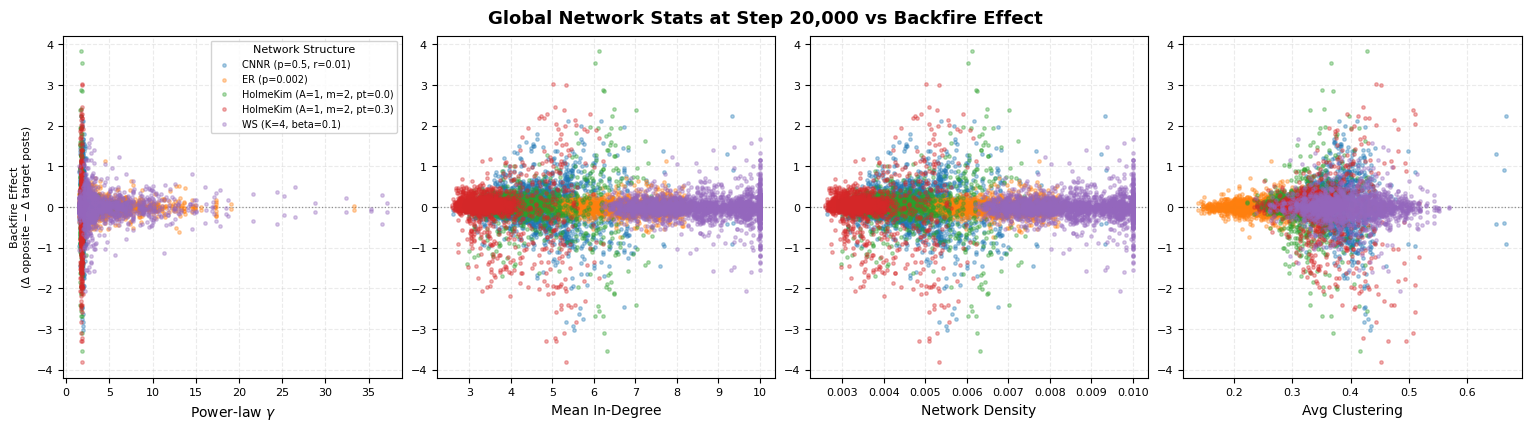

Saved → ./results/summary/scatter_global_stats_40000.png


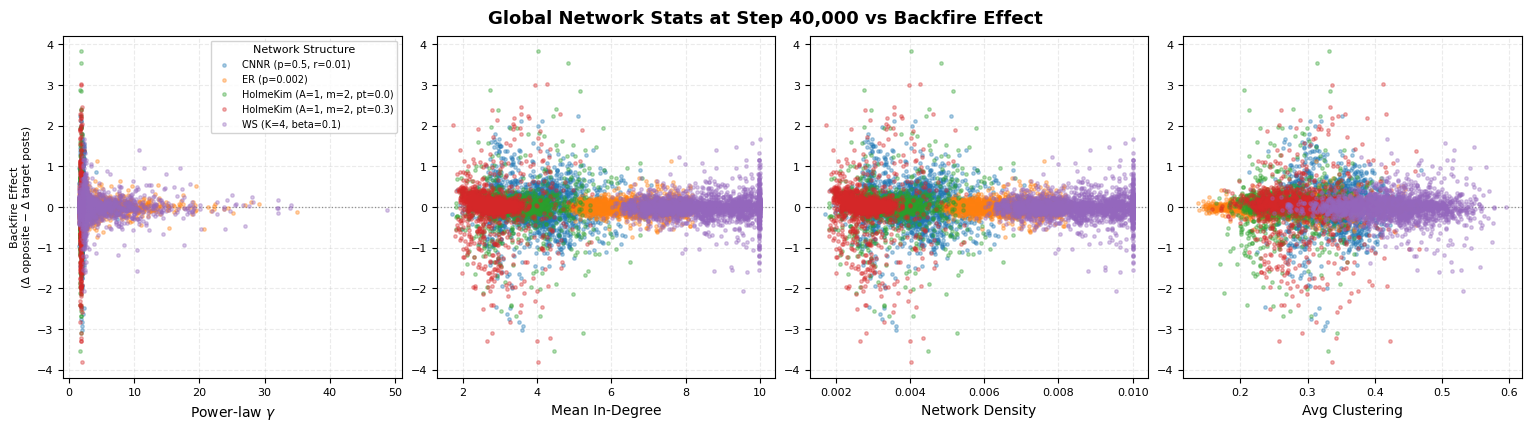

In [16]:
# ===========================================================================
# Plot 4 & 5 — Global NW Stats at Step 20 000 and 40 000 vs Backfire Effect
# ===========================================================================
# Two separate figures (one per step), each with 4 subplots (one per stat).
# Each point = one (seed, direction, condition).
# Color = network structure.  No connecting lines.
# ===========================================================================

for plot_step in [MANIP_STEP, END_STEP]:
    df_step = df_nw_merged[df_nw_merged['step'] == plot_step]

    fig, axes = plt.subplots(1, len(GLOBAL_STATS_COLS),
                             figsize=(len(GLOBAL_STATS_COLS) * 3.8, 4.2),
                             constrained_layout=True)

    for i, stat in enumerate(GLOBAL_STATS_COLS):
        ax = axes[i]
        for nw in NW_STRUCTURES:
            sub = df_step[df_step['nw_label'] == nw].dropna(subset=[stat])
            if sub.empty:
                continue
            ax.scatter(
                sub[stat], sub['backfire_effect'],
                color  = NW_COLOR[nw],
                s      = 6,
                alpha  = 0.35,
                label  = nw,
                zorder = 3,
                rasterized = True,
            )
        ax.axhline(0, color='#888888', linestyle=':', linewidth=0.9, zorder=1)
        ax.set_xlabel(GLOBAL_STAT_LABELS.get(stat, stat), fontsize=10)
        ax.set_ylabel('Backfire Effect\n(Δ opposite − Δ target posts)', fontsize=8) if i == 0 else ax.set_ylabel('')
        ax.grid(True, linestyle='--', alpha=0.25)
        ax.tick_params(labelsize=8)

    # legend on first subplot only
    axes[0].legend(title='Network Structure', title_fontsize=8,
                   fontsize=7, loc='best', framealpha=0.85)

    fig.suptitle(f'Global Network Stats at Step {plot_step:,} vs Backfire Effect',
                 fontsize=13, fontweight='bold')

    out_path = os.path.join(SUMMARY_ROOT, f'scatter_global_stats_{plot_step}.png')
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    print(f'Saved → {out_path}')
    plt.show()

Backfire group classification:
  Target success (BE ≤ 0)                                  n= 5421  range=[-3.813, -0.000]
  Weak backfire  (0 < BE ≤ 0.06)                           n= 2207  range=[+0.000, +0.059]
  Moderate backfire (0.06 < BE ≤ 0.16)                     n= 2207  range=[+0.059, +0.158]
  Strong backfire  (BE > 0.16)                             n= 2208  range=[+0.158, +3.831]


connectivity_5000step.csv : 109,638 rows loaded
follower_composition_5000step.csv : 109,638 rows loaded

Rows after join:
  nw_stats            : 108,387
  target_hub          : 108,387
  connectivity        : 108,387
  follower_comp       : 108,387


Z-scoring applied within (condition × step).

25 metrics to plot.


Saved → ./results/summary/nw_evolution_by_backfire_group.png


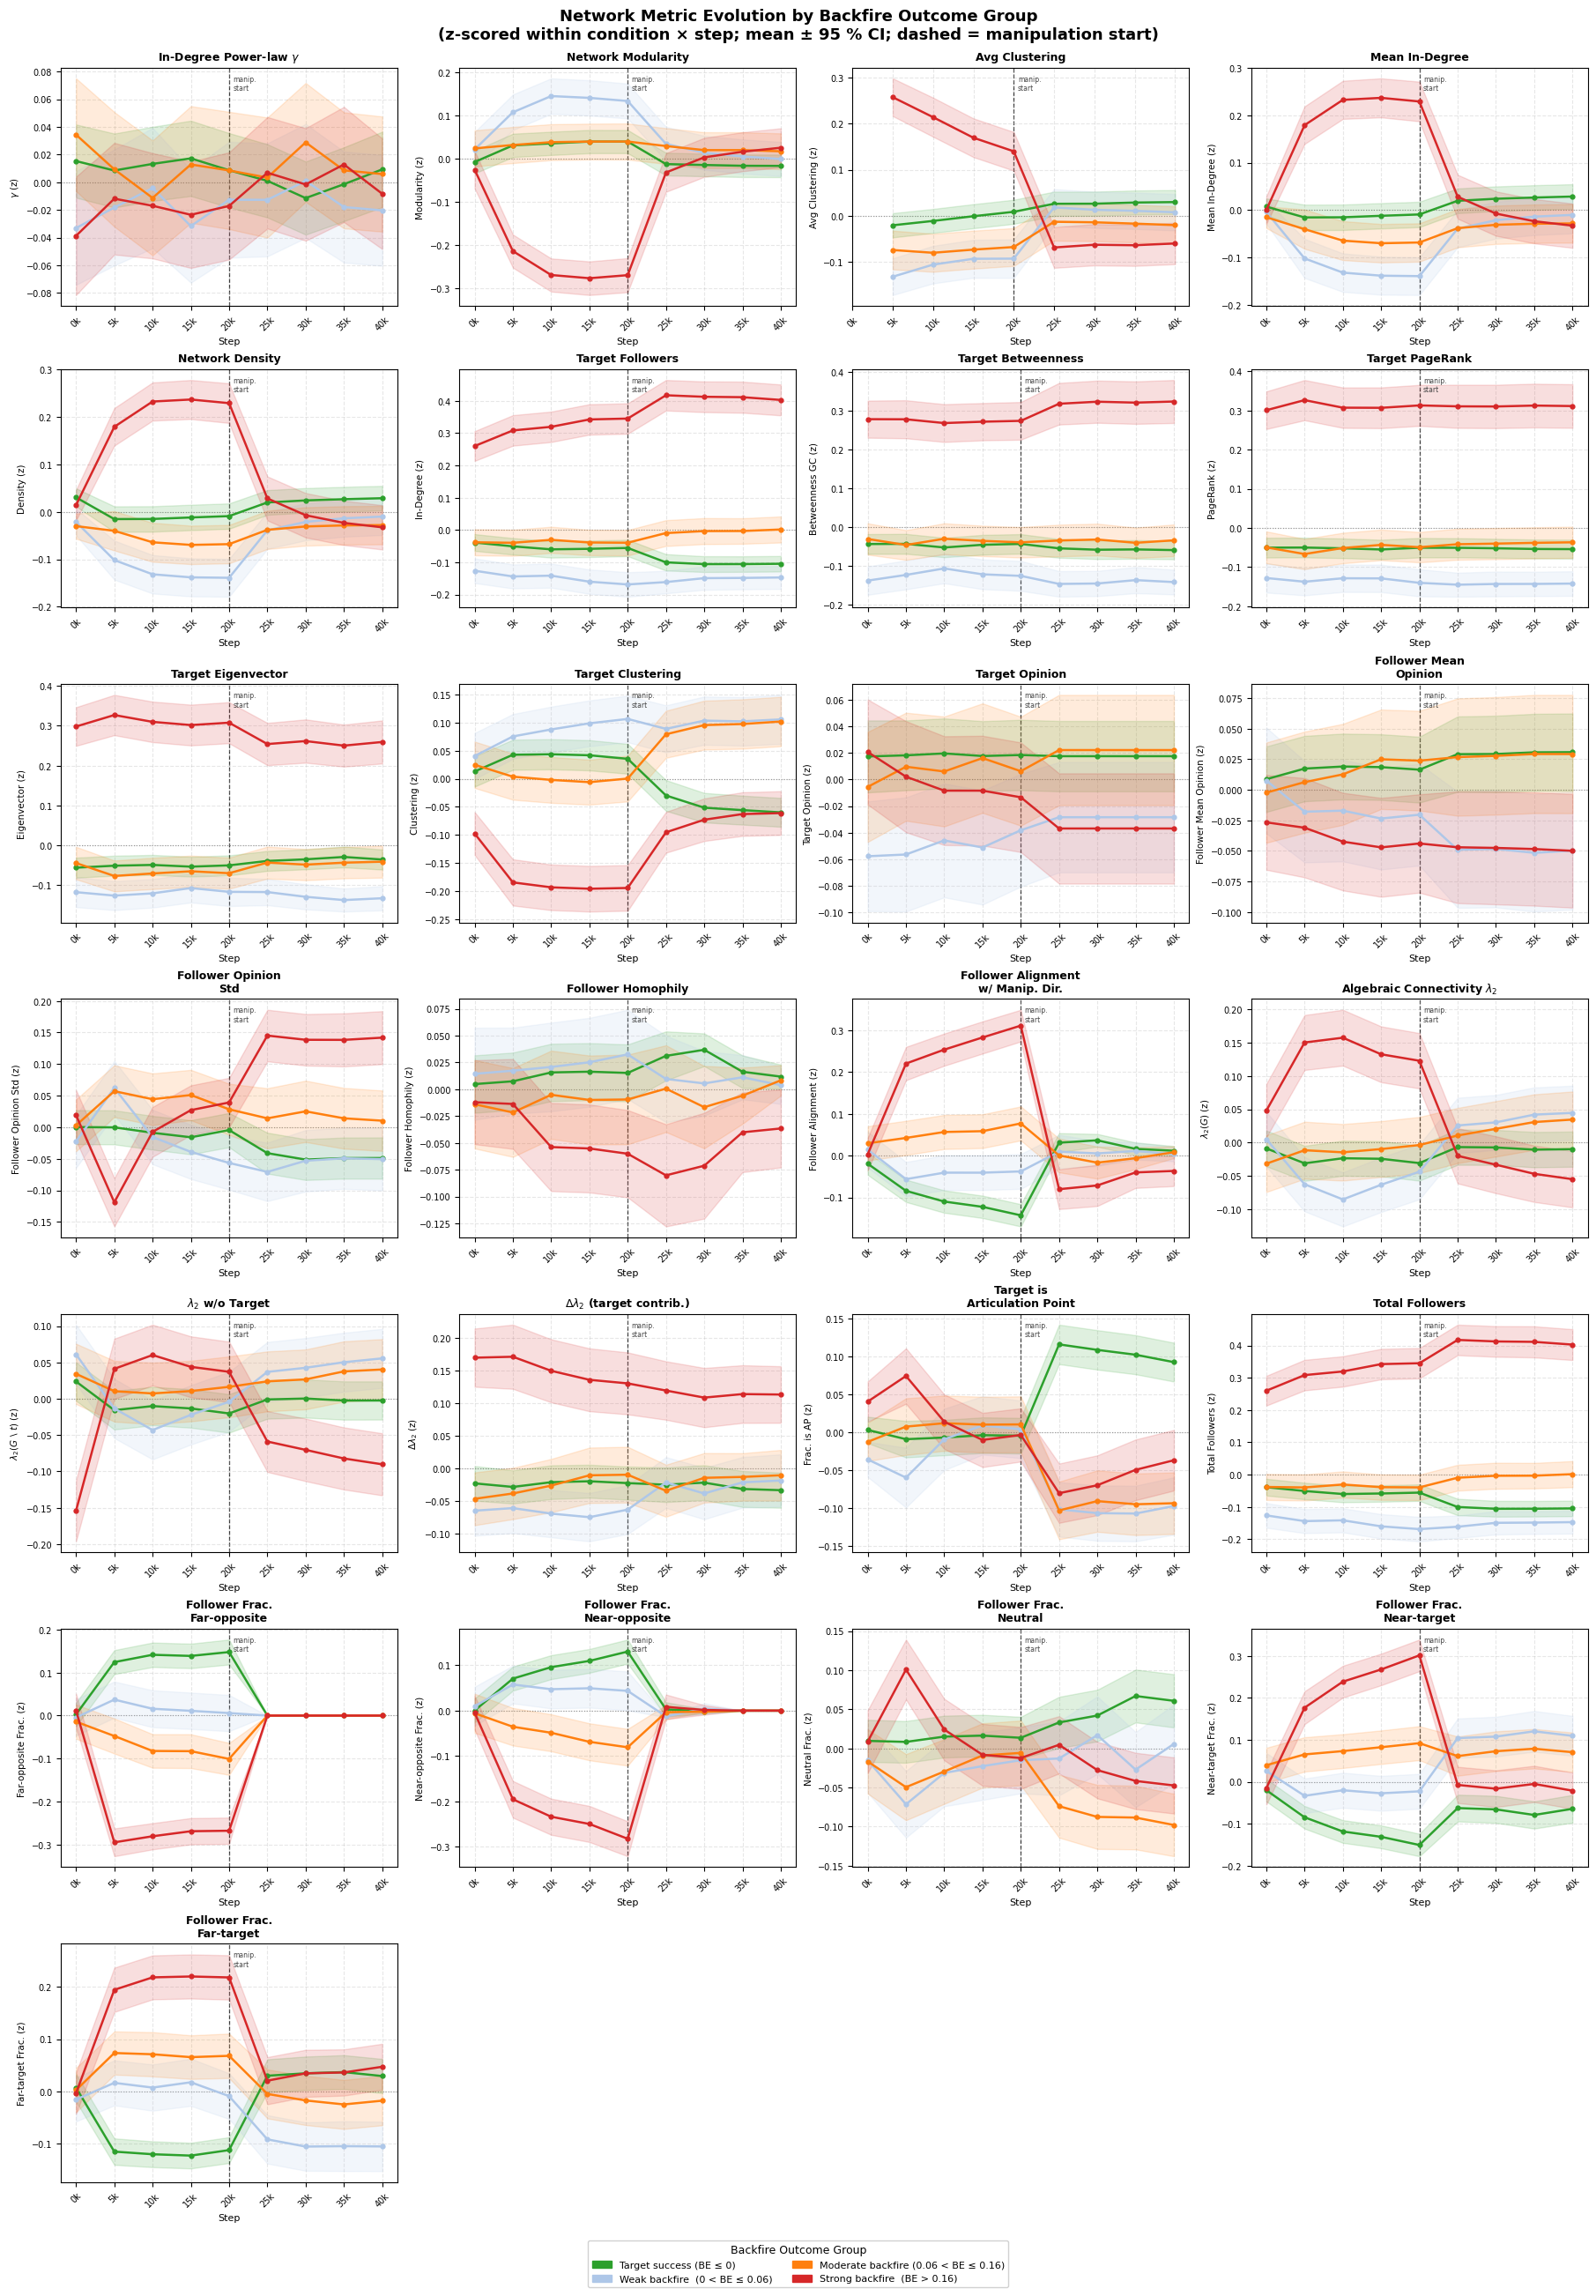

In [17]:
# ===========================================================================
# NW Metric Evolution by Backfire Outcome Group — full metric set
#
# Groups: split at 0, then terciles of positive backfire_effect values.
# NW metrics are z-scored within (condition × step) before aggregating,
# so topology / parameter mean differences don't dominate the lines.
#
# Covers all 5000-step metrics from save-results.ipynb:
#   nw_stats_5000step          → gamma, modularity, avg_clustering,
#                                mean_in_degree, density
#   target_hub_metrics_5000step→ in_degree, betweenness, pagerank,
#                                eigenvector, clustering, target_opinion,
#                                follower_mean_opinion, follower_opinion_std,
#                                follower_homophily_frac, follower_dir_alignment
#   connectivity_5000step      → lambda2_G, lambda2_G_minus_target,
#                                delta_lambda2, target_is_ap
#   follower_composition_5000step → total_followers + 5 opinion-class fracs
# ===========================================================================

import matplotlib.patches as mpatches

MIN_N = 5   # minimum seeds per group×step to draw a point

# ── 1. Classify seeds into backfire groups ──────────────────────────────────
_bf   = df_all['backfire_effect'].dropna()
_pos  = _bf[_bf > 0]
_p33  = float(_pos.quantile(1 / 3))
_p67  = float(_pos.quantile(2 / 3))

def _classify_bf(x):
    if x <= 0:      return 'target_increase'
    elif x <= _p33: return 'weak_backfire'
    elif x <= _p67: return 'moderate_backfire'
    else:           return 'strong_backfire'

_JOIN     = ['hash_id', 'seed', 'target_sign']
df_bf_grp = df_all[_JOIN + ['backfire_effect']].copy()
df_bf_grp['bf_group'] = df_bf_grp['backfire_effect'].map(_classify_bf)

_GRP_ORDER  = ['target_increase', 'weak_backfire', 'moderate_backfire', 'strong_backfire']
_GRP_LABELS = {
    'target_increase'  : f'Target success (BE ≤ 0)',
    'weak_backfire'    : f'Weak backfire  (0 < BE ≤ {_p33:.2f})',
    'moderate_backfire': f'Moderate backfire ({_p33:.2f} < BE ≤ {_p67:.2f})',
    'strong_backfire'  : f'Strong backfire  (BE > {_p67:.2f})',
}
_GRP_COLORS = {
    'target_increase'  : '#2ca02c',
    'weak_backfire'    : '#aec7e8',
    'moderate_backfire': '#ff7f0e',
    'strong_backfire'  : '#d62728',
}

print('Backfire group classification:')
for g in _GRP_ORDER:
    n    = int((df_bf_grp['bf_group'] == g).sum())
    vals = df_bf_grp[df_bf_grp['bf_group'] == g]['backfire_effect']
    print(f'  {_GRP_LABELS[g]:55s}  n={n:5d}  '
          f'range=[{vals.min():+.3f}, {vals.max():+.3f}]')

# ── 2. Load optional CSVs not already in memory ─────────────────────────────
_FOL_OPINION_COLS = ['far_opposite', 'near_opposite', 'neutral', 'near_target', 'far_target']

def _scan_and_load(filename):
    rows = []
    for _cfg in sorted(glob.glob(os.path.join(SUMMARY_ROOT, '*', '*', '*', 'config.yaml'))):
        _cdir = os.path.dirname(_cfg)
        _p    = os.path.join(_cdir, filename)
        if os.path.exists(_p):
            _d = pd.read_csv(_p)
            _d['hash_id'] = os.path.basename(_cdir)
            rows.append(_d)
    if not rows:
        return pd.DataFrame()
    df = pd.concat(rows, ignore_index=True)
    df['seed']        = df['seed'].astype(int)
    df['target_sign'] = df['target_sign'].astype(float)
    return df

_df_conn_raw = _scan_and_load('connectivity_5000step.csv')
_df_fol_raw  = _scan_and_load('follower_composition_5000step.csv')

for _name, _df in [('connectivity', _df_conn_raw), ('follower_composition', _df_fol_raw)]:
    if _df.empty:
        print(f'{_name}_5000step.csv : not found in any condition dir — skipping')
    else:
        print(f'{_name}_5000step.csv : {len(_df):,} rows loaded')

# ── 3. Join all time-series data with group labels ──────────────────────────
def _merge_grp(df):
    if df.empty:
        return df
    return df.merge(df_bf_grp[_JOIN + ['bf_group']], on=_JOIN, how='inner')

df_nw_evol   = _merge_grp(df_nw_all)
df_hub_evol  = _merge_grp(df_hub_all)
df_conn_evol = _merge_grp(_df_conn_raw)
df_fol_evol  = _merge_grp(_df_fol_raw)

print(f'\nRows after join:')
for _name, _df in [('nw_stats', df_nw_evol), ('target_hub', df_hub_evol),
                   ('connectivity', df_conn_evol), ('follower_comp', df_fol_evol)]:
    print(f'  {_name:20s}: {len(_df):,}')

# ── 3b. Z-score each metric within (condition × step) ──────────────────────
def _zscore_within_cond(df, cols):
    df = df.copy()
    for c in cols:
        if c not in df.columns:
            continue
        df[c] = df.groupby(['hash_id', 'step'])[c].transform(
            lambda x: (x - x.mean()) / x.std(ddof=1) if x.std(ddof=1) > 0 else x * 0.0
        )
    return df

_NW_ZCOLS   = ['gamma', 'modularity', 'avg_clustering', 'mean_in_degree', 'density']
_HUB_ZCOLS  = ['in_degree', 'betweenness_gc', 'pagerank', 'eigenvector', 'clustering',
                'target_opinion', 'follower_mean_opinion', 'follower_opinion_std',
                'follower_homophily_frac', 'follower_dir_alignment']
_CONN_ZCOLS = ['lambda2_G', 'lambda2_G_minus_target', 'delta_lambda2', 'target_is_ap']
_FOL_ZCOLS  = ['total_followers'] + _FOL_OPINION_COLS

df_nw_evol   = _zscore_within_cond(df_nw_evol,   _NW_ZCOLS)
df_hub_evol  = _zscore_within_cond(df_hub_evol,  _HUB_ZCOLS)
df_conn_evol = _zscore_within_cond(df_conn_evol, _CONN_ZCOLS)
df_fol_evol  = _zscore_within_cond(df_fol_evol,  _FOL_ZCOLS)
print('Z-scoring applied within (condition × step).')

# ── 4. Define all metrics to plot ───────────────────────────────────────────
# (source_df, column, y-axis label, subplot title)
_METRICS = [
    # --- Global NW stats ---
    (df_nw_evol,   'gamma',                   r'$\gamma$ (z)',                        r'In-Degree Power-law $\gamma$'),
    (df_nw_evol,   'modularity',              'Modularity (z)',                       'Network Modularity'),
    (df_nw_evol,   'avg_clustering',          'Avg Clustering (z)',                   'Avg Clustering'),
    (df_nw_evol,   'mean_in_degree',          'Mean In-Degree (z)',                   'Mean In-Degree'),
    (df_nw_evol,   'density',                 'Density (z)',                          'Network Density'),
    # --- Target hub structural ---
    (df_hub_evol,  'in_degree',               'In-Degree (z)',                        'Target Followers'),
    (df_hub_evol,  'betweenness_gc',          'Betweenness GC (z)',                   'Target Betweenness'),
    (df_hub_evol,  'pagerank',                'PageRank (z)',                         'Target PageRank'),
    (df_hub_evol,  'eigenvector',             'Eigenvector (z)',                      'Target Eigenvector'),
    (df_hub_evol,  'clustering',              'Clustering (z)',                       'Target Clustering'),
    # --- Target hub opinion ---
    (df_hub_evol,  'target_opinion',          'Target Opinion (z)',                   'Target Opinion'),
    (df_hub_evol,  'follower_mean_opinion',   'Follower Mean Opinion (z)',            'Follower Mean\nOpinion'),
    (df_hub_evol,  'follower_opinion_std',    'Follower Opinion Std (z)',             'Follower Opinion\nStd'),
    (df_hub_evol,  'follower_homophily_frac', 'Follower Homophily (z)',               'Follower Homophily'),
    (df_hub_evol,  'follower_dir_alignment',  'Follower Alignment (z)',               'Follower Alignment\nw/ Manip. Dir.'),
    # --- Connectivity ---
    (df_conn_evol, 'lambda2_G',               r'$\lambda_2(G)$ (z)',                 r'Algebraic Connectivity $\lambda_2$'),
    (df_conn_evol, 'lambda2_G_minus_target',  r'$\lambda_2(G\setminus t)$ (z)',      r'$\lambda_2$ w/o Target'),
    (df_conn_evol, 'delta_lambda2',           r'$\Delta\lambda_2$ (z)',              r'$\Delta\lambda_2$ (target contrib.)'),
    (df_conn_evol, 'target_is_ap',            'Frac. is AP (z)',                     'Target is\nArticulation Point'),
    # --- Follower opinion composition ---
    (df_fol_evol,  'total_followers',         'Total Followers (z)',                  'Total Followers'),
    (df_fol_evol,  'far_opposite',            'Far-opposite Frac. (z)',               'Follower Frac.\nFar-opposite'),
    (df_fol_evol,  'near_opposite',           'Near-opposite Frac. (z)',              'Follower Frac.\nNear-opposite'),
    (df_fol_evol,  'neutral',                 'Neutral Frac. (z)',                    'Follower Frac.\nNeutral'),
    (df_fol_evol,  'near_target',             'Near-target Frac. (z)',                'Follower Frac.\nNear-target'),
    (df_fol_evol,  'far_target',              'Far-target Frac. (z)',                 'Follower Frac.\nFar-target'),
]

# Drop metrics where source df is empty (connectivity / follower_comp not recorded)
_METRICS = [(df, c, yl, t) for df, c, yl, t in _METRICS
            if not df.empty and c in df.columns]
print(f'\n{len(_METRICS)} metrics to plot.')

# ── 5. Plot ─────────────────────────────────────────────────────────────────
_NCOLS = 4
_NROWS = int(np.ceil(len(_METRICS) / _NCOLS))

fig, axes = plt.subplots(_NROWS, _NCOLS,
                          figsize=(_NCOLS * 4.5, _NROWS * 3.6),
                          constrained_layout=True)
axes = np.array(axes).flatten()

for idx, (df_src, col, ylabel, title) in enumerate(_METRICS):
    ax    = axes[idx]
    steps = sorted(df_src['step'].unique())

    for g in _GRP_ORDER:
        sub = df_src[df_src['bf_group'] == g]
        _xs, _ys, _cis = [], [], []
        for s in steps:
            vals = sub[sub['step'] == s][col].dropna()
            if len(vals) < MIN_N:
                continue
            _xs.append(s)
            _ys.append(float(vals.mean()))
            _cis.append(1.96 * float(vals.sem()))

        if not _xs:
            continue
        _xs, _ys, _cis = np.array(_xs), np.array(_ys), np.array(_cis)
        ax.plot(_xs, _ys, color=_GRP_COLORS[g], linewidth=1.8,
                marker='o', markersize=3.5, zorder=3)
        ax.fill_between(_xs, _ys - _cis, _ys + _cis,
                         color=_GRP_COLORS[g], alpha=0.15, zorder=2)

    ax.axhline(0, color='#888888', linestyle=':', linewidth=0.8, zorder=1)
    ax.axvline(20000, color='#333333', linestyle='--', linewidth=0.9, zorder=1)
    ax.text(20500, 0.97, 'manip.\nstart', fontsize=5.5, color='#444444',
            va='top', transform=ax.get_xaxis_transform())
    ax.set_xlabel('Step', fontsize=8)
    ax.set_ylabel(ylabel, fontsize=7.5)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xticks(steps)
    ax.set_xticklabels([f'{int(s)//1000}k' for s in steps], fontsize=6, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(labelsize=7)

for j in range(len(_METRICS), len(axes)):
    axes[j].set_visible(False)

_handles = [
    mpatches.Patch(color=_GRP_COLORS[g], label=_GRP_LABELS[g])
    for g in _GRP_ORDER
]
fig.legend(handles=_handles,
           title='Backfire Outcome Group', title_fontsize=9, fontsize=8,
           loc='lower center', bbox_to_anchor=(0.5, -0.03),
           ncol=2, framealpha=0.9)

fig.suptitle(
    'Network Metric Evolution by Backfire Outcome Group\n'
    r'(z-scored within condition × step; mean ± 95 % CI; dashed = manipulation start)',
    fontsize=13, fontweight='bold',
)

out_path = os.path.join(SUMMARY_ROOT, 'nw_evolution_by_backfire_group.png')
plt.savefig(out_path, dpi=200, bbox_inches='tight')
print(f'Saved → {out_path}')
plt.show()
